# Predicción de reingreso hospitalario temprano en pacientes diabéticos

**Trabajo Final de Aprendizaje de Máquina** (CEIA, cohorte 27Co2026)

**Integrantes:**

- Florencia Lucca (flolucca@gmail.com)
- Mariano Reimondez (reimondezmariano@gmail.com)
- Carlos Lugones (lugo2012.cl@gmail.com)

## Fuente de los datos

*Diabetes 130-US Hospitals for Years 1999-2008*, UCI Machine Learning Repository:
https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

Artículo original del dataset: Strack, B. et al. (2014). *Impact of HbA1c Measurement on Hospital
Readmission Rates: Analysis of 70,000 Clinical Database Patient Records*. BioMed Research International.

## Objetivo de la investigación

Queremos saber si, con la información disponible al momento del alta, es posible anticipar qué pacientes
diabéticos van a volver a internarse dentro de los 30 días. Nos interesa por dos motivos. Un reingreso
temprano suele indicar que algo del tratamiento o del seguimiento no funcionó, y tiene un costo alto para el
paciente y para el hospital. Y si se identifica a tiempo a los pacientes de mayor riesgo, se puede priorizar
su seguimiento después del alta.

Concretamente, buscamos responder tres preguntas:

1. ¿Qué información del paciente y de la internación se asocia más con el reingreso temprano? (notebook 1)
2. ¿Alcanza una regla simple basada en el historial del paciente para anticiparlo, o hace falta un modelo
   que combine varias variables? (notebooks 2 y 3)
3. Si un modelo mejora a la regla simple, ¿cuánto mejora, qué aprendió y dónde sigue equivocándose?
   (notebook 4)


# Notebook 1 de 4: datos, EDA y selección de variables

El trabajo está dividido en cuatro notebooks que se leen en orden:

| Notebook | Pregunta que responde |
|---|---|
| **01_EDA_y_seleccion** | ¿Qué datos tenemos y qué variables sirven para predecir el reingreso? |
| 02_Planteo_y_basal | ¿Qué problema de aprendizaje resolvemos y cuál es la vara a superar? |
| 03_Modelos_y_ajuste | ¿Qué algoritmos probamos y cómo ajustamos sus hiperparámetros? |
| 04_Evaluacion_y_conclusiones | ¿Cuánto le ganan los algoritmos al basal, por qué y con qué límites? |

En este primer notebook se describe el dataset, se separan train y test agrupando por paciente y, solo con el
train, se exploran las variables, se tratan faltantes y outliers, se construyen variables nuevas y se eligen las
18 que pasan al modelado.

# Dataset Elegido:

## Diabetes 130-US Hospitals for Years 1999-2008

El conjunto de datos abarca diez años (1999-2008) de atención clínica en **130 hospitales y redes integradas de prestación de servicios sanitarios de EE. UU**. Cada fila corresponde a los historiales hospitalarios de pacientes diagnosticados con diabetes, a los que se les realizaron análisis de laboratorio, se les **administraron medicamentos y permanecieron ingresados hasta 14 días**. El objetivo es **determinar el reingreso precoz del paciente en los 30 días siguientes al alta**. El problema es importante por las siguientes razones. A pesar de que existen pruebas de alta calidad que demuestran una mejora en los resultados clínicos de los pacientes diabéticos que reciben diversas intervenciones preventivas y terapéuticas, **muchos pacientes no las reciben**. Esto puede atribuirse en parte a un tratamiento arbitrario de la diabetes en el ámbito hospitalario, que no presta la atención necesaria al control glucémico. La falta de una atención adecuada de la diabetes no solo aumenta los costes de gestión para los hospitales (al producirse **reingresos de los pacientes**), sino que también repercute en la morbilidad y la mortalidad de los pacientes, que pueden sufrir complicaciones asociadas a la diabetes.

Información adicional

El dataset representa diez años (1999–2008) de atención clínica en 130 hospitales y redes integradas de salud de Estados Unidos. Incluye más de 50 variables que representan resultados de pacientes y hospitales. La información fue extraída de la base de datos para los encuentros (episodios de atención) que cumplían con los siguientes criterios:

1. Es un encuentro de internación (una admisión hospitalaria).
2. Es un encuentro diabético, es decir, uno durante el cual se registró en el sistema algún tipo de diabetes como diagnóstico.
3. La duración de la internación fue de al menos 1 día y como máximo 14 días.
4. Se realizaron análisis de laboratorio durante el encuentro.
5. Se administraron medicamentos durante el encuentro.

Los datos contienen atributos como número de paciente, raza, género, edad, tipo de admisión, tiempo en el hospital, especialidad médica del médico que admitió al paciente, cantidad de análisis de laboratorio realizados, resultado del test de HbA1c, diagnóstico, cantidad de medicamentos, medicamentos para la diabetes, cantidad de visitas ambulatorias, de internación y de emergencia en el año previo a la hospitalización, etc.

## Diccionario de variables

Descripción de las 50 columnas del dataset, agrupadas por tema. Fuente: [UCI Machine
Learning Repository](https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008)
y Tabla 1 de Strack et al. (2014), *"Impact of HbA1c Measurement on Hospital
Readmission Rates"*, BioMed Research International.

### Identificadores

| Variable | Descripción |
|---|---|
| `encounter_id` | Identificador único de un encuentro (una internación) |
| `patient_nbr` | Identificador único de un paciente |

### Demográficas

| Variable | Descripción |
|---|---|
| `race` | Valores: Caucasian, Asian, African American, Hispanic, y other |
| `gender` | Valores: male, female, y unknown/invalid |
| `age` | Agrupada en intervalos de 10 años: [0,10), [10,20), ..., [90,100) |
| `weight` | Peso en libras (con ~97% de faltantes) |

### Datos de la internación

| Variable | Descripción |
|---|---|
| `admission_type_id` | Código entero, 8 valores presentes en este dataset: por ejemplo emergencia, urgente, electiva, recién nacido, no disponible |
| `discharge_disposition_id` | Código entero, 26 valores presentes en este dataset: por ejemplo alta a domicilio, fallecido, no disponible |
| `admission_source_id` | Código entero, 17 valores presentes en este dataset: por ejemplo derivación médica, guardia, transferencia desde otro hospital |
| `time_in_hospital` | Cantidad de días entre la admisión y el alta |
| `payer_code` | Código del pagador/obra social (con muchos faltantes) |
| `medical_specialty` | Especialidad médica del profesional que admitió al paciente |

### Actividad clínica durante la internación

| Variable | Descripción |
|---|---|
| `num_lab_procedures` | Cantidad de análisis de laboratorio realizados durante la internación |
| `num_procedures` | Cantidad de procedimientos (no de laboratorio) realizados |
| `num_medications` | Cantidad de medicamentos distintos administrados |
| `number_diagnoses` | Cantidad de diagnósticos registrados |
| `diag_1`, `diag_2`, `diag_3` | Diagnóstico primario, secundario y terciario (códigos ICD-9) |
| `max_glu_serum` | Resultado del test de glucosa en sangre (>200, >300, Normal, o no medido) |
| `A1Cresult` | Resultado del test de HbA1c (>7, >8, Normal, o no medido) |

### Historial previo (año anterior a la internación)

| Variable | Descripción |
|---|---|
| `number_outpatient` | Cantidad de visitas ambulatorias en el año previo |
| `number_emergency` | Cantidad de visitas de urgencia en el año previo |
| `number_inpatient` | Cantidad de internaciones previas en el año previo |

### Medicamentos (23 columnas, una por droga)

`metformin`, `repaglinide`, `nateglinide`, `chlorpropamide`, `glimepiride`, `acetohexamide`,
`glipizide`, `glyburide`, `tolbutamide`, `pioglitazone`, `rosiglitazone`, `acarbose`,
`miglitol`, `troglitazone`, `tolazamide`, `examide`, `citoglipton`, `insulin`,
`glyburide-metformin`, `glipizide-metformin`, `glimepiride-pioglitazone`,
`metformin-rosiglitazone`, `metformin-pioglitazone`

Cada una indica si esa droga fue recetada y si la dosis fue: **Up** (aumentada),
**Down** (disminuida), **Steady** (sin cambios) o **No** (no recetada).

### Resumen y variable objetivo

| Variable | Descripción |
|---|---|
| `change` | Si hubo algún cambio en la medicación para diabetes (Ch / No) |
| `diabetesMed` | Si se recetó algún medicamento para diabetes (Yes / No) |
| `readmitted` | **Variable objetivo**: NO (no reingresó), >30 (reingresó después de 30 días), <30 (reingresó antes de 30 días) |

---
# EDA

## Cómo está organizado este notebook

Ordenamos el análisis exploratorio alrededor de una pregunta que nos hicimos en cada paso:

> **¿Este número lo necesitamos para *diseñar* el split, o alimenta una decisión de *modelado*?**

Esa pregunta separa el EDA en dos bloques con reglas distintas:

| | **EDA estructural** (sección 1) | **EDA analítico** (sección 3) |
|---|---|---|
| **Cuándo** | Antes del split | Después del split, **solo sobre train** |
| **Qué incluye** | Dimensiones, `dtypes`, cómo vienen codificados los faltantes, % de nulos, cardinalidad, duplicados, estructura de identificadores, errores de carga | Distribuciones, momentos, umbrales de outliers, entropía, correlaciones, y todas las medidas de asociación contra el target |
| **Por qué ahí** | El split **depende** de esto: no se puede decidir agrupar por `patient_nbr` sin haber descubierto antes que `patient_nbr` se repite | Son estimaciones muestrales que alimentan decisiones de modelado; calcularlas con el test adentro sesga esas decisiones (*data snooping*) |

El principio que ordena todo el trabajo es más estricto que "no tocar el test": ningún estadístico que después
se use para transformar los datos (moda de imputación, umbral de winsorización, media y desvío del escalado,
medias del target encoding) se calcula con datos de test, y ninguna decisión de preprocesamiento se toma
mirando un número que haya visto el test.

## La selección de variables va antes de codificar

Decidimos calcular Chi², ANOVA F e información mutua después del split pero **antes de codificar**, para poder
descartar variables enteras aunque se pierda algo de granularidad. Por eso la selección (sección 6) va antes
de la codificación (sección 7). La decisión tiene tres consecuencias, que se desarrollan en la sección 6:

1. Cada criterio se aplica al tipo de variable que le corresponde: Chi² sobre tablas de contingencia reales,
   ANOVA F sobre numéricas e información mutua sobre ambas.
2. La unidad de decisión es la variable, no la columna codificada: no se conservan tres dummies sueltas de una
   variable descartando las otras quince.
3. Aceptamos perder algo de granularidad a cambio de un modelo más simple de explicar.

**Estructura del notebook:** 1 EDA estructural, 2 problema y split, 3 EDA analítico, 4 preprocesamiento,
5 ingeniería de variables, 6 selección de variables, 7 codificación, escalado y balance de clases. El modelado
continúa en el notebook 2.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.ticker as mtick
import seaborn as sns
import missingno as msno
from scipy import stats
from scipy.stats import chi2_contingency, pointbiserialr, kendalltau, f_oneway
from sklearn.model_selection import GroupShuffleSplit, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, MinMaxScaler
from sklearn.feature_selection import f_classif, chi2, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (ConfusionMatrixDisplay,
                             recall_score, precision_score, f1_score,
                             roc_auc_score, average_precision_score)
from statsmodels.stats.outliers_influence import variance_inflation_factor
import statsmodels.api as sm
import warnings

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 60)
RANDOM_STATE = 42

Matplotlib is building the font cache; this may take a moment.


# 1. EDA estructural (antes del split)

Este bloque cubre exclusivamente lo que hay que saber **para poder diseñar el split**: cuántas
filas y columnas hay, de qué tipo es cada variable, cómo vienen codificados los faltantes,
cuánta cardinalidad tiene cada categórica, si hay duplicados y, lo más importante, **cómo se
estructuran los identificadores**.

Ninguno de estos números es un estadístico que alimente una decisión de modelado: son
propiedades del archivo (conteos, tipos, unicidad) o reglas fijas de calidad de datos. Las
distribuciones, los umbrales de outliers y todo lo que cruza contra el target quedan para la
sección 3, ya con el split hecho.

## 1.1 Carga del dataset

In [2]:
data_set_path = "diabetic_data.csv"
data_set = pd.read_csv(data_set_path)

print(f"Dimensiones del dataset: {data_set.shape[0]} filas x {data_set.shape[1]} columnas")
data_set.head()

Dimensiones del dataset: 101766 filas x 50 columnas


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


## 1.2 Observaciones, variables y tipos de datos

En este dataset los valores faltantes **no** están representados como `NaN` sino con el string
`"?"` (una decisión de diseño de quien lo cargó). Se detectan y convierten para que Pandas no 
reporte cero nulos y todo el análisis posterior parta de una premisa falsa.

In [3]:
data_set = data_set.replace(r"^\s*\?\s*$", np.nan, regex=True)

print(f"Número de observaciones: {data_set.shape[0]}")
print(f"Número de variables: {data_set.shape[1]}")
print()
data_set.info()

Número de observaciones: 101766
Número de variables: 50

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      99493 non-null   str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    3197 non-null    str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                61510 non-null   str  
 11  medical_specialty         51817 non-null   str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            10

In [4]:
data_set.dtypes.value_counts()

str      37
int64    13
Name: count, dtype: int64

101.766 observaciones (encuentros hospitalarios) y 50 variables. La mayoría llega
como `object` (texto) o `int64`, pero varias de las `int64` son en realidad **códigos
categóricos** (`admission_type_id`, `discharge_disposition_id`, `admission_source_id`) y no
cantidades: promediarlos no tendría sentido médico.

### Recodificación determinística de tipos

Se aplican los mapeos **fijos** (diccionario código → significado, tipado nominal/ordinal) de
las variables codificadas como números o texto libre. Ninguno usa un estadístico calculado
sobre los datos: son correspondencias tomadas del diccionario de variables del dataset, por lo
que el resultado sería idéntico si se aplicaran por separado sobre train y test. Por eso pueden
ir antes del split sin riesgo alguno.

In [5]:
cols_texto = data_set.select_dtypes(include=["object", "string"]).columns.tolist()
for c in cols_texto:
    data_set[c] = data_set[c].str.strip()

cols_enteras = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
for c in cols_enteras:
    data_set[c] = data_set[c].astype(int)

for c in cols_texto:
    data_set[c] = data_set[c].astype("category")

print("Valores únicos de 'race':", sorted(data_set["race"].dropna().unique()))
print("Valores únicos de 'gender':", sorted(data_set["gender"].dropna().unique()))
data_set.dtypes.value_counts()

Valores únicos de 'race': ['AfricanAmerican', 'Asian', 'Caucasian', 'Hispanic', 'Other']
Valores únicos de 'gender': ['Female', 'Male', 'Unknown/Invalid']


int64       13
category    13
category     7
category     2
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64

In [6]:
mapa_admission_type = {
    1: "Emergency", 2: "Urgent", 3: "Elective", 4: "Newborn",
    5: "Not Available", 6: "NULL", 7: "Trauma Center", 8: "Not Mapped",
}
data_set["admission_type_id"] = pd.Categorical(
    data_set["admission_type_id"].astype(int).map(mapa_admission_type), ordered=False
)

mapa_discharge_disposition = {
    1: "Discharged to home", 2: "Discharged/transferred to another short term hospital",
    3: "Discharged/transferred to SNF", 4: "Discharged/transferred to ICF",
    5: "Discharged/transferred to another type of inpatient care institution",
    6: "Discharged/transferred to home with home health service", 7: "Left AMA",
    8: "Discharged/transferred to home under care of Home IV provider",
    9: "Admitted as an inpatient to this hospital",
    10: "Neonate discharged to another hospital for neonatal aftercare",
    11: "Expired", 12: "Still patient or expected to return for outpatient services",
    13: "Hospice / home", 14: "Hospice / medical facility",
    15: "Discharged/transferred within this institution to Medicare approved swing bed",
    16: "Discharged/transferred/referred another institution for outpatient services",
    17: "Discharged/transferred/referred to this institution for outpatient services",
    18: "NULL", 19: "Expired at home. Medicaid only, hospice.",
    20: "Expired in a medical facility. Medicaid only, hospice.",
    21: "Expired, place unknown. Medicaid only, hospice.",
    22: "Discharged/transferred to another rehab fac including rehab units of a hospital",
    23: "Discharged/transferred to a long term care hospital",
    24: "Discharged/transferred to a nursing facility certified under Medicaid but not certified under Medicare",
    25: "Not Mapped", 26: "Unknown/Invalid",
    27: "Discharged/transferred to a federal health care facility",
    28: "Discharged/transferred/referred to a psychiatric hospital of psychiatric distinct part unit of a hospital",
    29: "Discharged/transferred to a Critical Access Hospital (CAH)",
}
data_set["discharge_disposition_id"] = pd.Categorical(
    data_set["discharge_disposition_id"].astype(int).map(mapa_discharge_disposition), ordered=False
)

mapa_admission_source = {
    1: "Physician Referral", 2: "Clinic Referral", 3: "HMO Referral",
    4: "Transfer from a hospital", 5: "Transfer from a Skilled Nursing Facility (SNF)",
    6: "Transfer from another health care facility", 7: "Emergency Room",
    8: "Court/Law Enforcement", 9: "Not Available",
    10: "Transfer from a critical access hospital", 11: "Normal Delivery",
    12: "Premature Delivery", 13: "Sick Baby", 14: "Extramural Birth",
    15: "Not Available", 17: "NULL", 18: "Transfer From Another Home Health Agency",
    19: "Readmission to Same Home Health Agency", 20: "Not Mapped",
    21: "Unknown/Invalid",
    22: "Transfer from hospital inpt/same facility resulting in a separate claim",
    23: "Born inside this hospital", 24: "Born outside this hospital",
    25: "Transfer from Ambulatory Surgery Center", 26: "Transfer from Hospice",
}
data_set["admission_source_id"] = pd.Categorical(
    data_set["admission_source_id"].astype(int).map(mapa_admission_source), ordered=False
)

orden_age = ["[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)",
             "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"]
data_set["age"] = pd.Categorical(data_set["age"], categories=orden_age, ordered=True)

data_set["max_glu_serum"] = pd.Categorical(data_set["max_glu_serum"],
                                           categories=["Norm", ">200", ">300"], ordered=True)
data_set["A1Cresult"] = pd.Categorical(data_set["A1Cresult"],
                                       categories=["Norm", ">7", ">8"], ordered=True)

def agrupar_diag(codigo):
    codigo = str(codigo)
    if codigo == "nan":
        return np.nan
    if codigo.startswith("V"):
        return "Factores de salud"
    if codigo.startswith("E"):
        return "Causas externas"
    try:
        c = float(codigo)
    except ValueError:
        return "Otro"
    if 390 <= c <= 459: return "Circulatorio"
    if 460 <= c <= 519: return "Respiratorio"
    if 520 <= c <= 579: return "Digestivo"
    if 250 <= c < 251: return "Diabetes"
    if 800 <= c <= 999: return "Lesiones/cirugia traumatologica"
    if 580 <= c <= 629: return "Genitourinario"
    if 710 <= c <= 739: return "Musculoesqueletico"
    if 140 <= c <= 239: return "Neoplasias"
    return "Otro"

for c in ["diag_1", "diag_2", "diag_3"]:
    data_set[c] = pd.Categorical(data_set[c].apply(agrupar_diag))

data_set["readmitted"] = data_set["readmitted"].astype("category")

print("dtypes finales (muestra):")
data_set[["admission_type_id", "discharge_disposition_id", "age", "diag_1", "readmitted"]].dtypes

dtypes finales (muestra):


admission_type_id           category
discharge_disposition_id    category
age                         category
diag_1                      category
readmitted                  category
dtype: object

Nota: `max_glu_serum` y `A1Cresult` se registran por ahora **sin** la categoría "No medido", porque
agregarla es *tratamiento* de faltantes y va en la sección 4.1. Acá sólo se fija el orden real
entre sus valores medidos (`Norm` < `>200`/`>7` < `>300`/`>8`).

## 1.3 Inventario de valores faltantes y su mecanismo (MCAR / MAR / MNAR / estructural)

Contar nulos es una propiedad del archivo, no un estadístico de modelado: `weight` falta en el
97% de las filas independientemente de qué partición se mire. Clasificar el mecanismo es un
juicio de dominio. Ambas cosas pertenecen al bloque estructural, y además condicionan qué
columnas van a sobrevivir al preprocesamiento.

In [7]:
nulos = data_set.isnull().sum()
nulos_pct = (nulos / len(data_set) * 100).round(2)
resumen_nulos = pd.DataFrame({"nulos": nulos, "% nulos": nulos_pct})
resumen_nulos = resumen_nulos[resumen_nulos["nulos"] > 0].sort_values("% nulos", ascending=False)
resumen_nulos

,nulos,% nulos
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


| Columna | % Faltante | Mecanismo probable | Justificación |
|---|---|---|---|
| `weight` | ~97% | **MNAR / estructural** | No se pesa de rutina a un paciente internado salvo indicación médica puntual. La ausencia depende del propio dato (si pesar era relevante clínicamente). |
| `max_glu_serum`, `A1Cresult` | ~95% / ~83% | **MNAR / estructural** | Son análisis que sólo se piden según criterio médico o protocolo del hospital; su ausencia está ligada a la decisión clínica, no al azar. |
| `medical_specialty` | ~49% | **MAR** | Depende de si el hospital registra la especialidad del médico tratante (varía por institución/época), algo relacionado con otras variables observadas más que con el valor en sí. |
| `payer_code` | ~40% | **MAR** | Vinculado a procesos administrativos del hospital, no al estado clínico del paciente. |
| `race` | ~2% | **MCAR (aprox.)** | Proporción baja y sin patrón evidente; probablemente omisión aleatoria al completar el formulario. |
| `diag_1/2/3` | <2% | **MCAR** | Muy pocos casos, probablemente errores de carga puntuales. |

### Evidencia visual de los patrones de faltantes (`missingno`)

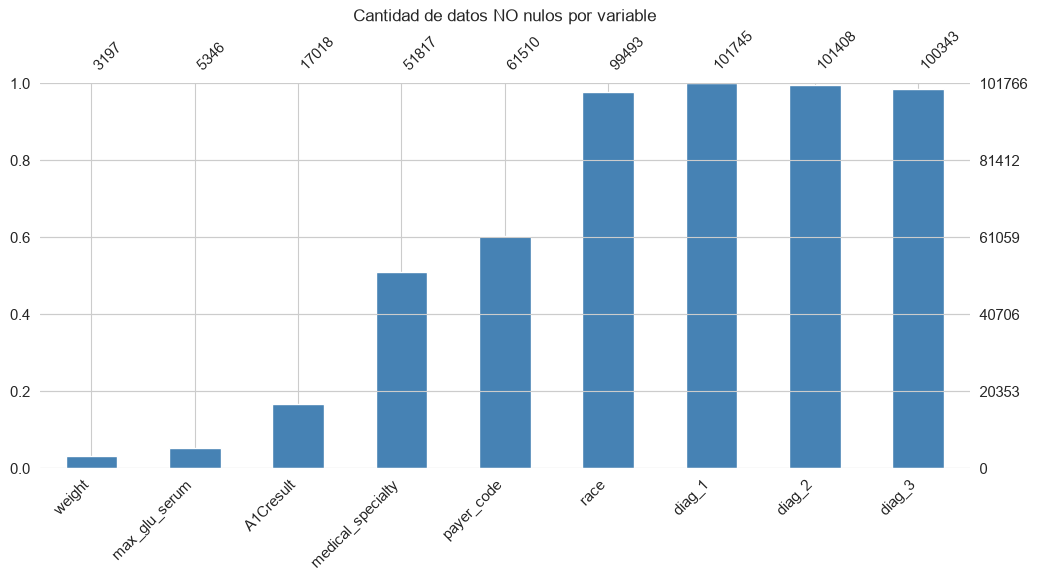

In [8]:
cols_con_faltantes = ["weight", "max_glu_serum", "A1Cresult", "medical_specialty",
                      "payer_code", "race", "diag_1", "diag_2", "diag_3"]

msno.bar(data_set[cols_con_faltantes], fontsize=11, figsize=(12, 5), color="steelblue")
plt.title("Cantidad de datos NO nulos por variable")
plt.show()

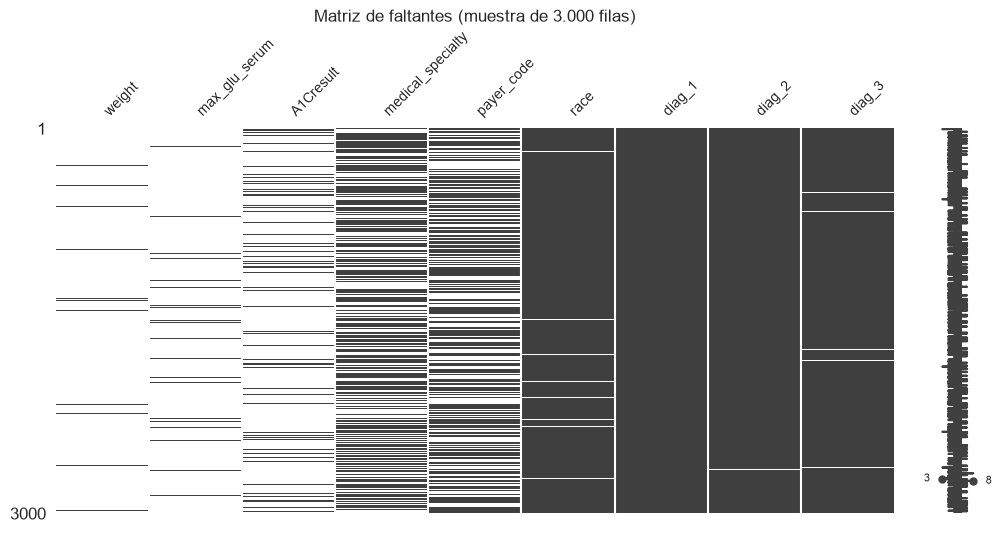

In [9]:
muestra = data_set[cols_con_faltantes].sample(3000, random_state=RANDOM_STATE)
msno.matrix(muestra, figsize=(12, 5), fontsize=10)
plt.title("Matriz de faltantes (muestra de 3.000 filas)")
plt.show()

**Lectura.** `weight` está prácticamente vacía, y `max_glu_serum` y `A1Cresult` faltan en la gran mayoría de las
filas. `medical_specialty` y `payer_code` faltan en alrededor de la mitad y del 40 % respectivamente, y en la
matriz aparecen como franjas que se alternan sin coincidir con las de otras columnas. `race` y los tres
diagnósticos están casi completos. El gráfico siguiente mide si los faltantes de distintas columnas tienden a
darse juntos.

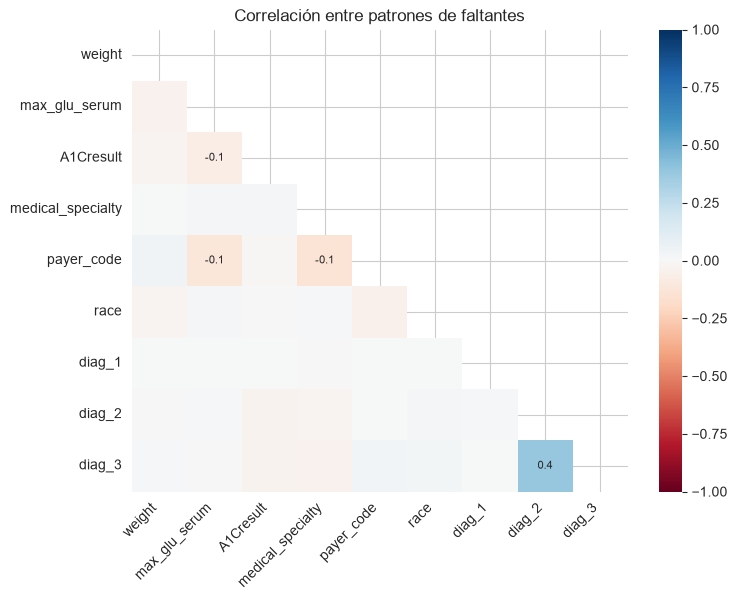

In [10]:
msno.heatmap(data_set[cols_con_faltantes], fontsize=10, figsize=(8, 6))
plt.title("Correlación entre patrones de faltantes")
plt.show()

El heatmap de correlación de nulos no muestra pares fuertemente correlacionados
(todos los valores cercanos a 0), consistente con la clasificación de la tabla: `weight`,
`max_glu_serum`/`A1Cresult`, `medical_specialty`/`payer_code` y `race` faltan por **motivos
independientes entre sí** (decisión clínica, proceso administrativo, omisión aleatoria) y no por
un único proceso subyacente que afecte a varias columnas a la vez.

## 1.4 Cardinalidad de las variables categóricas

La cardinalidad es una propiedad estructural (cuántos valores distintos admite la columna) y es
lo que va a determinar la **estrategia de codificación** de la sección 7: las nominales con **10 o
más categorías** van a target encoding y las de menos de 10 a one-hot. Conviene tenerla a la vista
desde el principio para poder justificar después dónde cae ese corte.

In [11]:
cols_categoricas = data_set.select_dtypes(include=["category"]).columns.tolist()
card = (pd.DataFrame({
            "n_categorias": [data_set[c].nunique(dropna=True) for c in cols_categoricas],
            "% nulos": [data_set[c].isna().mean() * 100 for c in cols_categoricas],
        }, index=cols_categoricas)
        .round(2)
        .sort_values("n_categorias", ascending=False))
card.head(20)

,n_categorias,% nulos
medical_specialty,72,49.08
discharge_disposition_id,26,0.00
admission_source_id,17,0.00
payer_code,17,39.56
diag_1,11,0.02
diag_2,11,0.35
diag_3,11,1.40
age,10,0.00
weight,9,96.86
admission_type_id,8,0.00


La cardinalidad no se reparte de forma continua, se reparte en **dos grupos
separados por un hueco**. Arriba están `medical_specialty` (72 categorías),
`discharge_disposition_id` (26), `admission_source_id` (17), `payer_code` (17) y los tres
diagnósticos (11 cada uno), todas nominales que un one-hot haría explotar. Abajo, `race` (5), las
23 columnas de droga y el resto de las categóricas tienen 2-5 categorías. **No hay ninguna variable
nominal entre 6 y 10 categorías**, y ese hueco es el que va a permitir fijar el umbral de la
sección 7 sin elegirlo a medida. `age` (10) y `weight` (9) caen en el medio pero no compiten en esa
decisión: `age` es ordinal y `weight` se elimina por faltantes. Esta tabla se retoma tal cual en la
sección 7.

## 1.5 Duplicados y estructura de identificadores

**Este es el punto que determina cómo hay que partir el dataset**, y por eso tiene que resolverse
antes del split y no después. Dos preguntas:

1. ¿Hay filas repetidas? Si las hubiera y se eliminaran *después* de partir, una copia podría
   quedar en train y otra en test.
2. ¿Un mismo paciente aparece en más de una fila? Si es así, un split aleatorio por fila
   repartiría encuentros del mismo paciente entre ambas particiones, y el modelo podría
   "reconocerlo" en test: una fuga de información a nivel paciente.

In [12]:
print(f"Encuentros (filas) duplicados por encounter_id: {data_set['encounter_id'].duplicated().sum()}")
print(f"Filas totalmente duplicadas (todas las columnas iguales): {data_set.duplicated().sum()}")
print()
print(f"Filas totales:                {data_set.shape[0]}")
print(f"Pacientes únicos:             {data_set['patient_nbr'].nunique()}")
print(f"Filas con patient_nbr repetido: {data_set['patient_nbr'].duplicated().sum()}")
print()
enc_por_paciente = data_set["patient_nbr"].value_counts()
print("Distribución de encuentros por paciente:")
print(enc_por_paciente.value_counts().sort_index().head(10).rename("cantidad de pacientes"))
print(f"\nMáximo de encuentros de un mismo paciente: {enc_por_paciente.max()}")

Encuentros (filas) duplicados por encounter_id: 0
Filas totalmente duplicadas (todas las columnas iguales): 0

Filas totales:                101766
Pacientes únicos:             71518
Filas con patient_nbr repetido: 30248

Distribución de encuentros por paciente:
count
1     54745
2     10434
3      3328
4      1421
5       717
6       346
7       207
8       111
9        70
10       42
Name: cantidad de pacientes, dtype: int64

Máximo de encuentros de un mismo paciente: 40


**Lectura y consecuencia directa sobre el diseño del split:** no hay `encounter_id` repetidos ni
filas 100% idénticas, así que **no hay duplicados por eliminar**. Pero unos 30.000 registros
corresponden a pacientes que ya aparecen en otra fila: los `patient_nbr` repetidos **no son
duplicados**, son internaciones distintas del mismo paciente a lo largo de 10 años.

Esto descarta `train_test_split` simple y obliga a un **split agrupado por `patient_nbr`**
(sección 2). Es exactamente el tipo de decisión que el EDA estructural tiene que habilitar: sin
esta celda, la sección 2 no tendría fundamento.

## 1.6 Errores e inconsistencias: limpieza general

Última pieza estructural: valores que no corresponden a ninguna categoría válida. Es una regla
fija de calidad de datos (no depende de ningún estadístico), y **define el universo del estudio**,
por lo que tiene que aplicarse antes de partir el dataset.

In [13]:
print("Casos con gender inválido ('Unknown/Invalid'):", (data_set["gender"] == "Unknown/Invalid").sum())

print("Filas antes:", data_set.shape[0])
data_set = data_set[data_set["gender"] != "Unknown/Invalid"].copy()
data_set["gender"] = data_set["gender"].cat.remove_unused_categories()
print("Filas después:", data_set.shape[0])

Casos con gender inválido ('Unknown/Invalid'): 3
Filas antes: 101766
Filas después: 101763


# 2. Problema de ML supervisado y split del dataset

## 2.1 Planteo del problema

**Tipo de problema:** clasificación supervisada (binaria).

**Variable target:** `readmitted`, que en el dataset original tiene 3 clases (`NO`, `>30`, `<30`).
Siguiendo el objetivo clínico planteado por los autores del dataset (anticipar el **reingreso
temprano (dentro de los 30 días del alta)**, que es el que más impacto tiene en costos y en la
salud del paciente), se recodifica como problema **binario**:

- `1` → el paciente reingresó dentro de los 30 días (`<30`)
- `0` → no reingresó o reingresó después de 30 días (`NO` o `>30`)

**Features:** el resto de las variables clínicas y administrativas, excluyendo identificadores
sin valor predictivo (`encounter_id`, `patient_nbr`).

**Por qué se plantea acá y no después:** la recodificación es una regla fija (`readmitted == "<30"`),
no un estadístico, y hace falta tener el target definido **antes** de partir para poder verificar
que la proporción de clase positiva quede comparable entre train y test.

**Por qué es razonable como problema de ML:** anticipar el riesgo de reingreso permite priorizar
el seguimiento post-alta en los pacientes de mayor riesgo. La sección 3 va a mostrar que ninguna
variable aislada separa fuerte al target, que es justamente el escenario donde un modelo
multivariado aporta más que una regla simple.

In [14]:
data_set["readmitted_temprano"] = (data_set["readmitted"] == "<30").astype(int)

print(data_set["readmitted"].value_counts())
print()
print("Variable target binaria 'readmitted_temprano':")
data_set["readmitted_temprano"].value_counts(normalize=True).round(3)

readmitted
NO     54861
>30    35545
<30    11357
Name: count, dtype: int64

Variable target binaria 'readmitted_temprano':


readmitted_temprano
0    0.888
1    0.112
Name: proportion, dtype: float64

## 2.2 Split train / test (agrupado por paciente)

Como se estableció en 1.5, un mismo `patient_nbr` tiene varios encuentros. Se usa
`GroupShuffleSplit` agrupando por paciente para garantizar que **ningún paciente aparezca en
ambas particiones**.

`GroupShuffleSplit` no soporta estratificar por clase de forma nativa, así que se verifica
manualmente que la proporción de clase positiva quede razonablemente similar entre train y test.

A partir de esta celda, **el conjunto de test queda congelado**: no se lo grafica, no se calculan
estadísticos sobre él, y no vuelve a aparecer hasta la evaluación final (M9, notebook 4).

In [15]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.30, random_state=RANDOM_STATE)
idx_train_split, idx_test_split = next(gss.split(data_set, groups=data_set["patient_nbr"]))

encounter_ids_train = set(data_set.iloc[idx_train_split]["encounter_id"])
data_set["_es_train"] = data_set["encounter_id"].isin(encounter_ids_train)

pacientes_train = set(data_set.loc[data_set["_es_train"], "patient_nbr"])
pacientes_test = set(data_set.loc[~data_set["_es_train"], "patient_nbr"])
encounters_train = set(data_set.loc[data_set["_es_train"], "encounter_id"])
encounters_test = set(data_set.loc[~data_set["_es_train"], "encounter_id"])

assert len(pacientes_train & pacientes_test) == 0, "Hay pacientes repetidos entre train y test"
assert len(encounters_train & encounters_test) == 0, "Hay encuentros repetidos entre train y test"
assert len(encounters_train) + len(encounters_test) == data_set.shape[0], "Se perdieron o duplicaron filas"

print("Pacientes en ambas particiones (debe ser 0):", len(pacientes_train & pacientes_test))
print("Encuentros en ambas particiones (debe ser 0):", len(encounters_train & encounters_test))
print(f"Filas train: {data_set['_es_train'].sum()} ({data_set['_es_train'].mean()*100:.1f}%)")
print(f"Filas test:  {(~data_set['_es_train']).sum()} ({(~data_set['_es_train']).mean()*100:.1f}%)")

tasa_train = data_set.loc[data_set["_es_train"], "readmitted_temprano"].mean()
tasa_test = data_set.loc[~data_set["_es_train"], "readmitted_temprano"].mean()
print(f"\nTasa de reingreso <30d - train: {tasa_train*100:.2f}%  test: {tasa_test*100:.2f}%")

Pacientes en ambas particiones (debe ser 0): 0
Encuentros en ambas particiones (debe ser 0): 0
Filas train: 71583 (70.3%)
Filas test:  30180 (29.7%)

Tasa de reingreso <30d - train: 11.27%  test: 10.91%


In [16]:
# A partir de acá, TODO el analisis exploratorio de la seccion 3 usa unicamente df_train.
df_train = data_set[data_set["_es_train"]].copy()

print(f"df_train: {df_train.shape[0]} filas x {df_train.shape[1]} columnas")
print(f"Pacientes distintos en train: {df_train['patient_nbr'].nunique()}")

df_train: 71583 filas x 52 columnas
Pacientes distintos en train: 50060


# 3. EDA analítico (después del split, solo sobre train)

Todo lo que sigue son **estimaciones muestrales**: momentos, límites de outliers, entropías,
correlaciones y medidas de asociación contra el target. Cambian según qué filas se miren, y
alimentan decisiones concretas de modelado (qué variables winsorizar, cuáles discretizar, cuáles
descartar por redundancia). Por eso se calculan exclusivamente sobre `df_train`.

## 3.1 Variables numéricas: estadística descriptiva y forma de la distribución

In [17]:
cols_numericas = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                  "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]

resumen = pd.DataFrame({
    "media": df_train[cols_numericas].mean(),
    "mediana": df_train[cols_numericas].median(),
    "desvio_std": df_train[cols_numericas].std(),
    "MAD": df_train[cols_numericas].apply(lambda s: stats.median_abs_deviation(s)),
    "asimetria": df_train[cols_numericas].apply(lambda s: stats.skew(s)),
    "curtosis": df_train[cols_numericas].apply(lambda s: stats.kurtosis(s)),
}).round(2)
resumen

,media,mediana,desvio_std,MAD,asimetria,curtosis
time_in_hospital,4.39,4.0,2.98,2.0,1.14,0.87
num_lab_procedures,43.18,44.0,19.64,13.0,-0.24,-0.25
num_procedures,1.33,1.0,1.70,1.0,1.33,0.89
num_medications,16.00,15.0,8.11,5.0,1.32,3.45
number_outpatient,0.37,0.0,1.28,0.0,8.74,144.09
number_emergency,0.20,0.0,0.99,0.0,24.48,1259.94
number_inpatient,0.65,0.0,1.30,0.0,3.71,21.77
number_diagnoses,7.43,8.0,1.93,1.0,-0.87,-0.08


**Lectura:** `num_lab_procedures` y `number_diagnoses` son las más simétricas del grupo (asimetría
negativa leve). `num_procedures`, `num_medications` y `time_in_hospital` muestran asimetría
positiva moderada. En cambio `number_outpatient`, `number_emergency` y `number_inpatient`
presentan **asimetría positiva muy fuerte**: la mayoría de los pacientes en 0 y una cola larga de
pocos pacientes con muchas visitas previas.

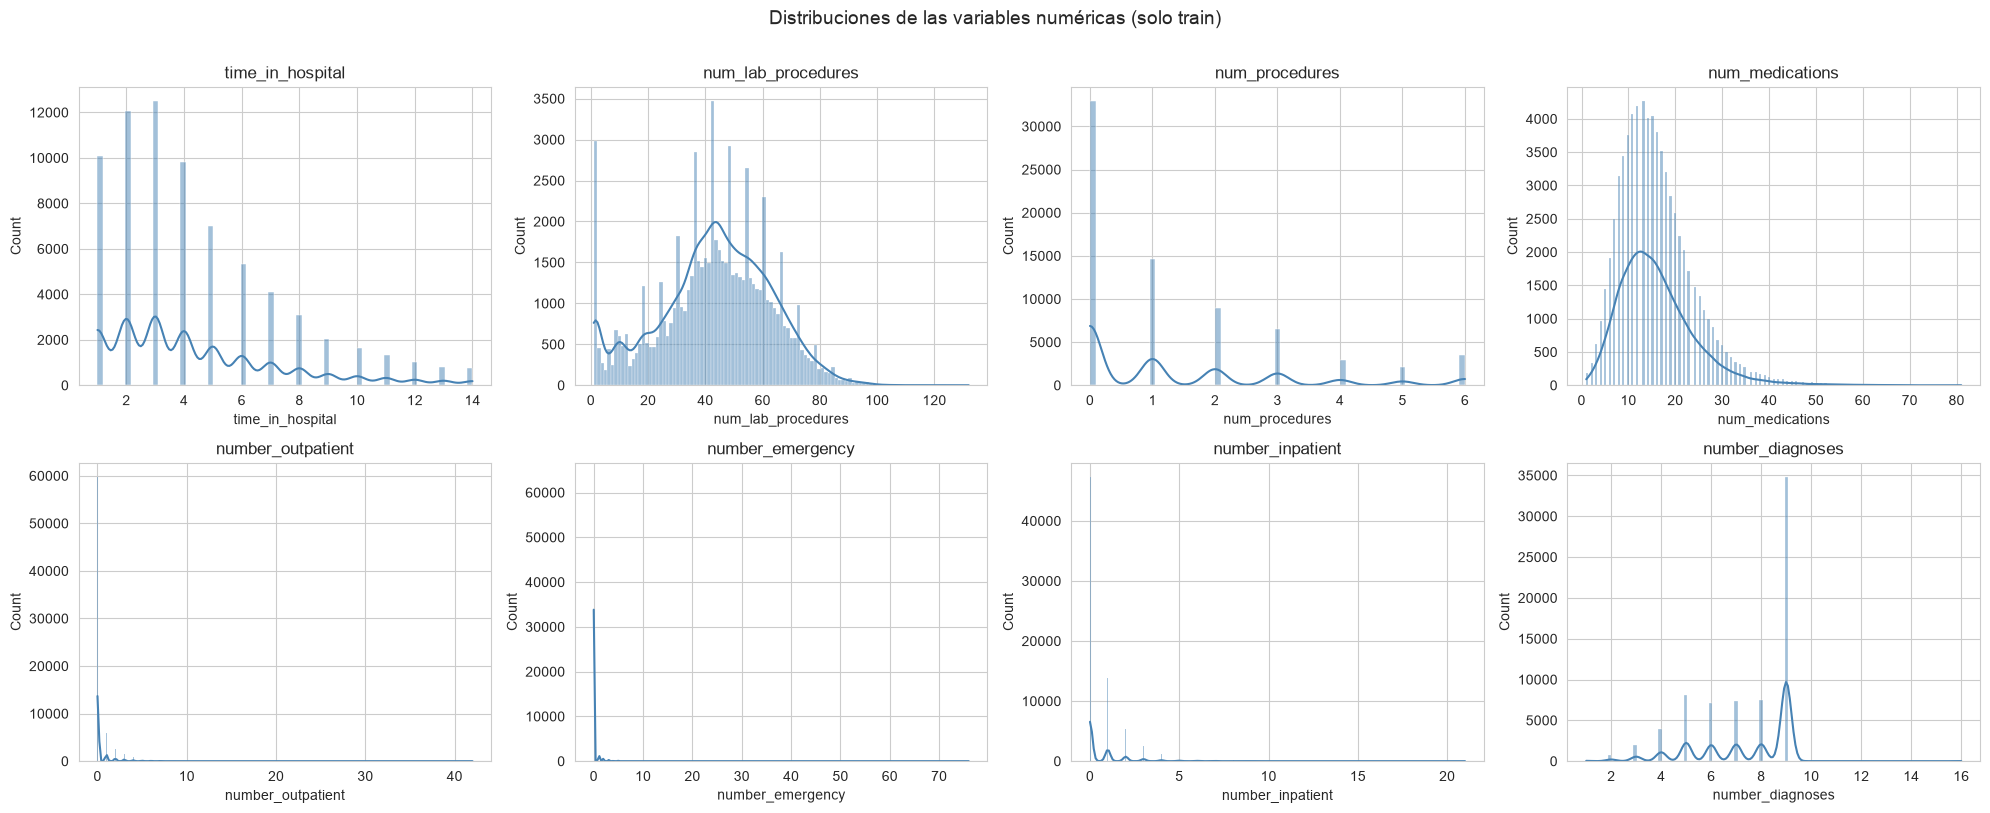

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, col in zip(axes.flat, cols_numericas):
    sns.histplot(df_train[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
fig.suptitle("Distribuciones de las variables numéricas (solo train)", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

In [19]:
df_train[cols_numericas].describe(percentiles=[.1, .25, .5, .75, .9, .95]).round(2)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
count,71583.00,71583.00,71583.00,71583.00,71583.00,71583.00,71583.00,71583.00
mean,4.39,43.18,1.33,16.00,0.37,0.20,0.65,7.43
std,2.98,19.64,1.70,8.11,1.28,0.99,1.30,1.93
min,1.00,1.00,0.00,1.00,0.00,0.00,0.00,1.00
10%,1.00,14.00,0.00,7.00,0.00,0.00,0.00,5.00
25%,2.00,32.00,0.00,10.00,0.00,0.00,0.00,6.00
50%,4.00,44.00,1.00,15.00,0.00,0.00,0.00,8.00
75%,6.00,57.00,2.00,20.00,0.00,0.00,1.00,9.00
90%,9.00,67.00,4.00,26.00,1.00,1.00,2.00,9.00
95%,11.00,73.00,5.00,31.00,2.00,1.00,3.00,9.00


**Lectura de los histogramas y la tabla.** El tiempo de internación se concentra entre 1 y 4 días (mediana de 4)
y decrece después. `num_lab_procedures` es la única variable aproximadamente simétrica, con una media de 43
análisis, aunque tiene un pico en valores muy bajos. `num_medications` está sesgada a la derecha: la mediana es 15
pero llega a 81. Los tres conteos de visitas previas tienen casi toda la masa en 0. `number_diagnoses` se acumula
en 9, probablemente porque el sistema de registro admitía hasta nueve diagnósticos por internación.

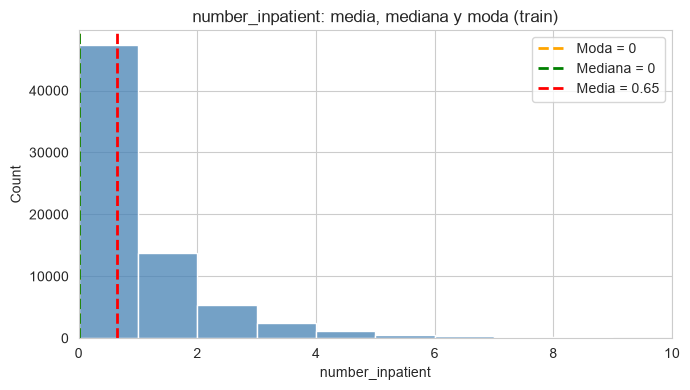

In [20]:
col = "number_inpatient"
media, mediana, moda = df_train[col].mean(), df_train[col].median(), df_train[col].mode()[0]

fig, ax = plt.subplots(figsize=(7, 4))
sns.histplot(df_train[col], bins=range(0, 12), ax=ax, color="steelblue")
ax.axvline(moda, color="orange", ls="--", lw=2, label=f"Moda = {moda:.0f}")
ax.axvline(mediana, color="green", ls="--", lw=2, label=f"Mediana = {mediana:.0f}")
ax.axvline(media, color="red", ls="--", lw=2, label=f"Media = {media:.2f}")
ax.set_xlim(0, 10)
ax.set_title("number_inpatient: media, mediana y moda (train)")
ax.legend()
plt.tight_layout()
plt.show()

Mediana y moda coinciden en 0, mientras que la media queda desplazada hacia la
derecha por la cola de pacientes con varias internaciones previas. Es un caso típico donde la mediana
representa mejor al paciente "promedio".

## 3.2 Identificación de outliers (IQR, solo train)

El criterio de rango intercuartílico usa Q1 y Q3, que **son estadísticos muestrales**: por eso
esta celda pertenece al bloque analítico y se calcula sobre train. Los límites que salen de acá
son los que después justifican el tratamiento de la sección 4.2 (winsorización) y la
discretización de la 5.1.

In [21]:
def resumen_outliers_iqr(serie):
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = serie[(serie < lim_inf) | (serie > lim_sup)]
    return lim_inf, lim_sup, len(outliers), len(outliers) / len(serie) * 100

cols_outliers_interes = ["num_lab_procedures", "number_emergency", "number_inpatient", "num_medications"]
for col in cols_outliers_interes:
    lim_inf, lim_sup, n_out, pct_out = resumen_outliers_iqr(df_train[col])
    print(f"{col:22s} límites=({lim_inf:6.1f}, {lim_sup:6.1f})  "
          f"outliers={n_out:6d} ({pct_out:5.2f}%)  max={df_train[col].max()}")

num_lab_procedures     límites=(  -5.5,   94.5)  outliers=   147 ( 0.21%)  max=132
number_emergency       límites=(   0.0,    0.0)  outliers=  8075 (11.28%)  max=76
number_inpatient       límites=(  -1.5,    2.5)  outliers=  5094 ( 7.12%)  max=21
num_medications        límites=(  -5.0,   35.0)  outliers=  1780 ( 2.49%)  max=81


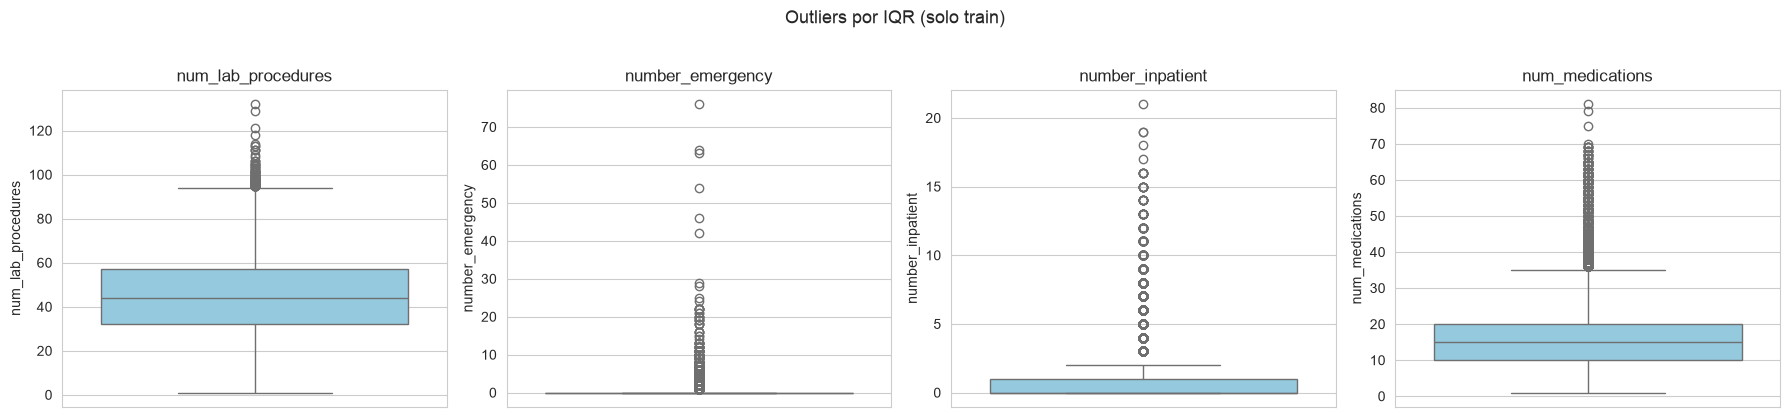

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cols_outliers_interes):
    sns.boxplot(y=df_train[col], ax=ax, color="skyblue")
    ax.set_title(col)
fig.suptitle("Outliers por IQR (solo train)", fontsize=13, y=1.03)
plt.tight_layout()
plt.show()

**Interpretación clínica (identificación, sin tratar todavía):**

- `num_lab_procedures`: el máximo observado es plausible en una internación larga con múltiples estudios.
- `number_emergency` y `number_inpatient`: la mayoría de los pacientes tiene 0 visitas previas, así
  que IQR marca como "outlier" a *cualquier valor positivo*. Es un artefacto de una distribución
  muy asimétrica, no un error de carga: son justamente los pacientes de alto riesgo, la población
  que más interesa para el problema de reingreso. **Esta observación es la que motiva discretizarlas
  en la sección 5.1.**
- `num_medications`: asimetría más moderada; los valores altos reflejan polimedicación clínicamente relevante.
- Ninguno parece un **error** de carga: son valores clínicamente posibles. El tratamiento se
  decide y aplica en la sección 4.2.

### 3.2.1 Verificación: ¿cambia algo por haber calculado esto sobre train en vez de sobre todo el dataset?

La sección 3 se calcula únicamente sobre train porque son estimaciones muestrales. Cabe la
pregunta inversa: ¿esa restricción metodológica cambia algo en la práctica, o el 70% de los
datos ya alcanza para estimar bien estos estadísticos? Se compara acá con los mismos cálculos
sobre el dataset completo, usado únicamente para esta verificación.

In [23]:
comparacion_iqr = []
for col in cols_outliers_interes:
    li_tr, ls_tr, _, _ = resumen_outliers_iqr(df_train[col])
    li_full, ls_full, _, _ = resumen_outliers_iqr(data_set[col])
    comparacion_iqr.append({
        "variable": col,
        "lim_inf (train)": round(li_tr, 2), "lim_inf (completo)": round(li_full, 2),
        "lim_sup (train)": round(ls_tr, 2), "lim_sup (completo)": round(ls_full, 2),
    })
display(pd.DataFrame(comparacion_iqr))

corr_train = df_train[cols_numericas].corr()
corr_full = data_set[cols_numericas].corr()
dif_max = (corr_train - corr_full).abs().values.max()
print(f"\nDiferencia máxima absoluta entre las matrices de correlación (train vs. completo): {dif_max:.4f}")

,variable,lim_inf (train),lim_inf (completo),lim_sup (train),lim_sup (completo)
0,num_lab_procedures,-5.5,-8.0,94.5,96.0
1,number_emergency,0.0,0.0,0.0,0.0
2,number_inpatient,-1.5,-1.5,2.5,2.5
3,num_medications,-5.0,-5.0,35.0,35.0



Diferencia máxima absoluta entre las matrices de correlación (train vs. completo): 0.0136


## 3.3 Variables categóricas: cardinalidad y entropía de Shannon

La entropía mide qué tan "repartidas" están las observaciones entre categorías: cerca de 0 = una
categoría domina casi todo; cerca del máximo = distribución equilibrada. Es una métrica calculada
sobre frecuencias observadas, así que va acá y no en la sección 1.

In [24]:
def entropia_shannon(serie):
    counts = serie.value_counts(dropna=True)
    probs = counts / counts.sum()
    h = stats.entropy(probs, base=2)
    h_max = np.log2(len(counts))
    return counts.shape[0], h, h_max, (h / h_max if h_max > 0 else np.nan)

cols_categoricas_interes = ["race", "gender", "age", "admission_type_id",
                            "discharge_disposition_id", "admission_source_id",
                            "medical_specialty", "payer_code", "diag_1", "diag_2", "diag_3",
                            "max_glu_serum", "A1Cresult", "readmitted"]

filas = []
for c in cols_categoricas_interes:
    n_cat, h, h_max, h_norm = entropia_shannon(df_train[c])
    filas.append([c, n_cat, round(h, 2), round(h_max, 2), round(h_norm, 2)])

pd.DataFrame(filas, columns=["variable", "n_categorias", "entropia", "entropia_max", "entropia_normalizada"])

,variable,n_categorias,entropia,entropia_max,entropia_normalizada
0,race,5,1.01,2.32,0.44
1,gender,2,1.00,1.00,1.00
2,age,10,2.66,3.32,0.80
3,admission_type_id,8,1.84,3.00,0.61
4,discharge_disposition_id,26,2.10,4.70,0.45
5,admission_source_id,17,1.70,4.09,0.42
6,medical_specialty,72,3.57,6.17,0.58
7,payer_code,17,2.46,4.09,0.60
8,diag_1,11,2.90,3.46,0.84
9,diag_2,11,2.72,3.46,0.79


`gender` y `age` tienen entropía normalizada alta (categorías balanceadas). `race` y
`admission_source_id` están dominadas por 1-2 categorías. `medical_specialty`, con 70+ categorías,
tiene alta cardinalidad pero baja entropía relativa. El propio target, `readmitted`, tiene entropía
normalizada baja: ya se ve acá que las 3 clases **no están balanceadas**, algo que se retoma en 7.5.

## 3.4 Visualizaciones univariadas

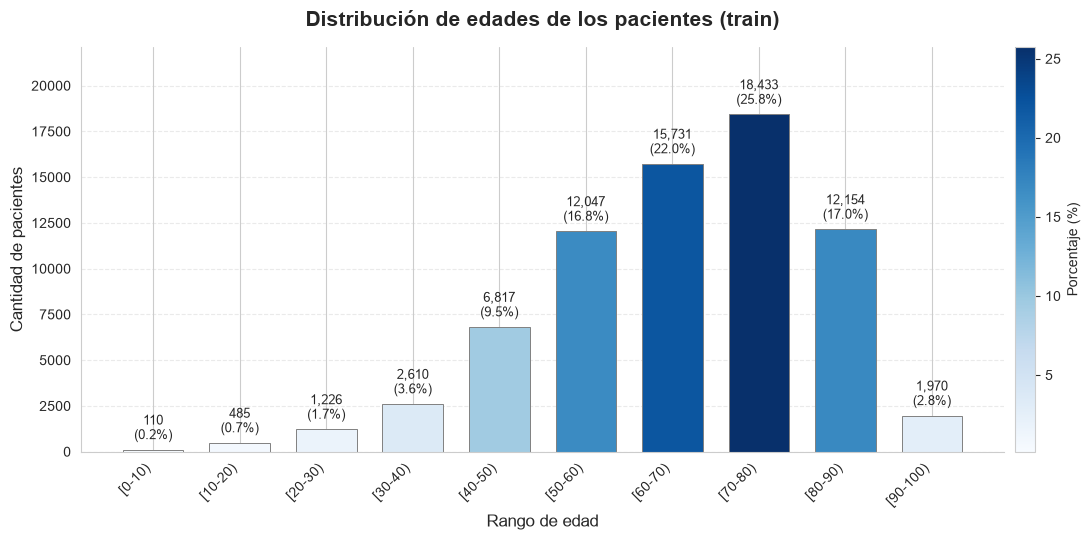

In [25]:
counts = df_train["age"].value_counts().sort_index()
total = counts.sum()
pcts = counts.values / total * 100

norm = mpl.colors.Normalize(vmin=pcts.min(), vmax=pcts.max())
cmap = mpl.colormaps["Blues"]
colores = [cmap(norm(p)) for p in pcts]

fig, ax = plt.subplots(figsize=(12, 5.5))
bars = ax.bar(counts.index.astype(str), counts.values, color=colores,
              edgecolor="gray", linewidth=0.7, width=0.7)
for bar, valor, pct in zip(bars, counts.values, pcts):
    ax.text(bar.get_x() + bar.get_width() / 2, valor + total * 0.005,
            f"{valor:,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=9)

ax.set_xlabel("Rango de edad", fontsize=12)
ax.set_ylabel("Cantidad de pacientes", fontsize=12)
ax.set_title("Distribución de edades de los pacientes (train)", fontsize=15, fontweight="bold", pad=15)
plt.xticks(rotation=45, ha="right")
ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_ylim(0, counts.max() * 1.2)

smap = mpl.cm.ScalarMappable(cmap=cmap, norm=norm); smap.set_array([])
cbar = fig.colorbar(smap, ax=ax, pad=0.01); cbar.set_label("Porcentaje (%)", fontsize=10)
plt.tight_layout()
plt.show()

**Por qué este gráfico:** barras (categórica ordinal con pocas categorías), con
una escala de color que refuerza el porcentaje de cada barra.

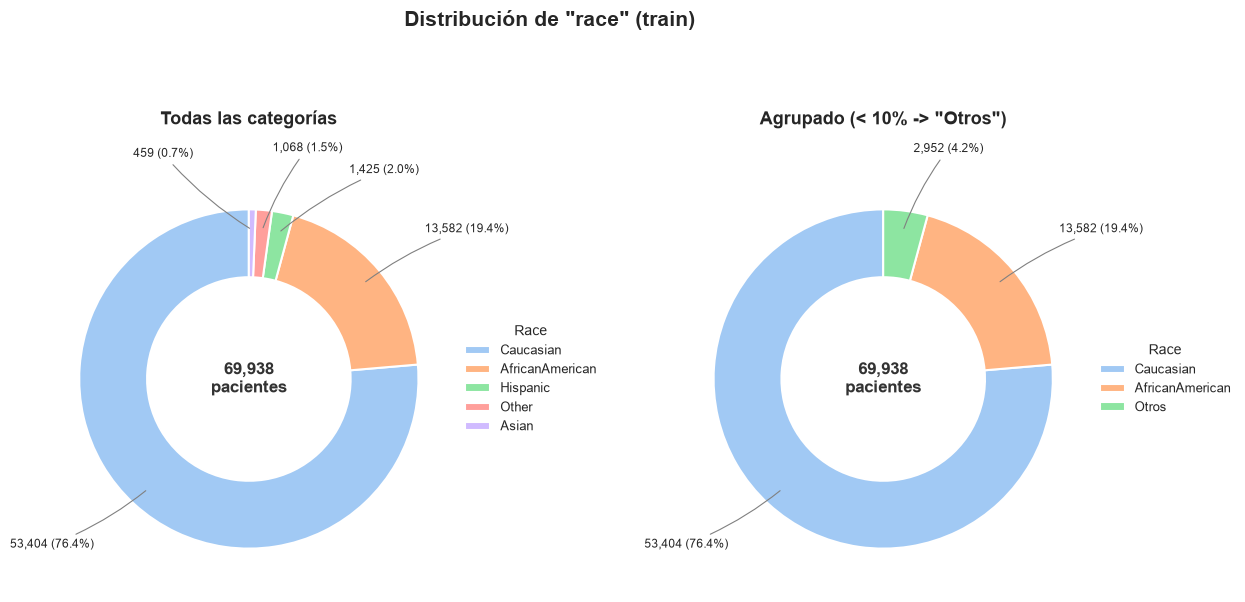

In [26]:
def plot_donut(data, column, group_others=False, threshold=0.10, title=None,
               palette="pastel", ax=None, radius=0.85, min_gap=20,
               radio_texto_mult=1.35, fontsize=8.5, title_pad=30):
    counts = data[column].value_counts()
    if group_others:
        pct = counts / counts.sum()
        major = counts[pct >= threshold].copy()
        minor = counts[pct < threshold]
        if len(minor) > 0:
            major["Otros"] = minor.sum()
        counts = major.sort_values(ascending=False)
    else:
        counts = counts.sort_values(ascending=False)

    total = counts.sum()
    colores = sns.color_palette(palette, len(counts))
    if ax is None:
        fig, ax = plt.subplots(figsize=(6, 5.5))

    wedges, _ = ax.pie(counts.values, startangle=90, colors=colores, radius=radius,
                       wedgeprops=dict(width=0.4 * radius, edgecolor="white", linewidth=1.5))

    angulos_true = np.array([(w.theta2 + w.theta1) / 2 for w in wedges])
    angulos_disp = angulos_true.copy()
    for _ in range(500):
        cambiado = False
        for i in range(1, len(angulos_disp)):
            gap = angulos_disp[i] - angulos_disp[i - 1]
            if gap < min_gap:
                falta = (min_gap - gap) / 2
                angulos_disp[i] += falta; angulos_disp[i - 1] -= falta
                cambiado = True
        if not cambiado:
            break

    radio_texto = radius * radio_texto_mult
    for i, wedge in enumerate(wedges):
        ang_true, ang_disp = angulos_true[i], angulos_disp[i]
        x_true, y_true = np.cos(np.radians(ang_true)), np.sin(np.radians(ang_true))
        x_disp, y_disp = np.cos(np.radians(ang_disp)), np.sin(np.radians(ang_disp))
        alineacion = "right" if x_disp < 0 else "left"
        valor = counts.values[i]; pct = valor / total * 100
        ax.annotate(f"{valor:,} ({pct:.1f}%)",
                    xy=(x_true * radius * 0.88, y_true * radius * 0.88),
                    xytext=(x_disp * radio_texto, y_disp * radio_texto),
                    horizontalalignment=alineacion, fontsize=fontsize,
                    arrowprops=dict(arrowstyle="-", color="gray", lw=0.8,
                                    connectionstyle="arc3,rad=0.08"))

    ax.text(0, 0, f"{total:,}\npacientes", ha="center", va="center",
            fontsize=12, fontweight="bold", color="#333333")
    ax.legend(wedges, counts.index, title=column.capitalize(), loc="center left",
              bbox_to_anchor=(1.05, 0.5), frameon=False, fontsize=9)
    ax.set_title(title if title else f'Distribución de "{column}"',
                 fontsize=13, fontweight="bold", pad=title_pad)
    ax.set_xlim(-2.3, 2.3); ax.set_ylim(-2.1, 2.1); ax.axis("equal")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
fig.subplots_adjust(wspace=0.7, top=0.76, bottom=0.05)
plot_donut(df_train, "race", group_others=False, title="Todas las categorías", ax=axes[0])
plot_donut(df_train, "race", group_others=True, threshold=0.10,
           title='Agrupado (< 10% -> "Otros")', ax=axes[1])
fig.suptitle('Distribución de "race" (train)', fontsize=15, fontweight="bold", y=1.02)
plt.show()

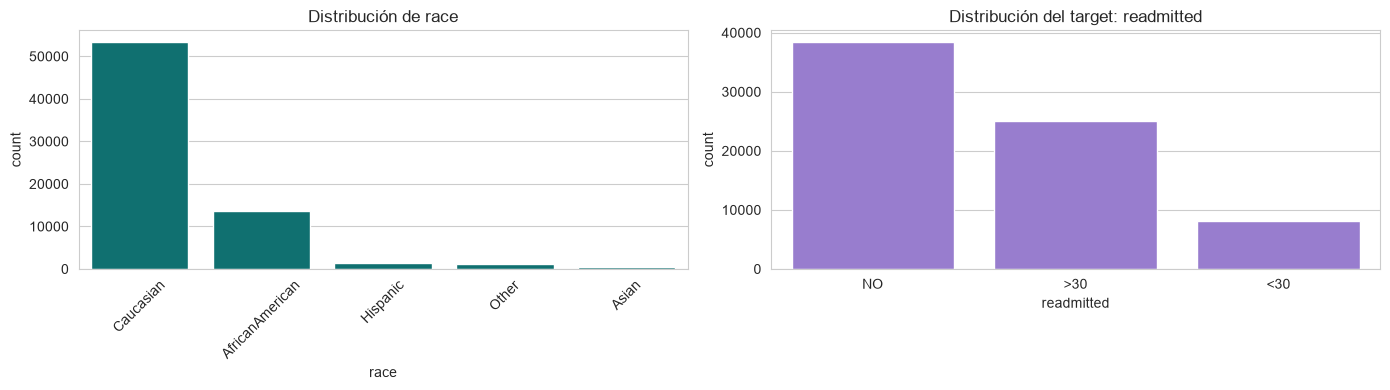

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.countplot(data=df_train, x="race", order=df_train["race"].value_counts().index,
              ax=axes[0], color="teal")
axes[0].set_title("Distribución de race"); axes[0].tick_params(axis="x", rotation=45)
sns.countplot(data=df_train, x="readmitted", order=["NO", ">30", "<30"],
              ax=axes[1], color="mediumpurple")
axes[1].set_title("Distribución del target: readmitted")
plt.tight_layout()
plt.show()

**Por qué este gráfico:** dona/torta para `race` (categórica nominal, interesa la composición
proporcional del total) y barras para el conteo por categoría. Se ve a simple vista que
`readmitted` está desbalanceado, algo que se cuantifica en 7.5.

## 3.5 Visualizaciones bivariadas contra el target

#### `age` vs `readmitted`

In [28]:
tabla_cruzada = pd.crosstab(df_train["age"], df_train["readmitted"], normalize="index") * 100
tabla_cruzada = tabla_cruzada[["NO", ">30", "<30"]]
tabla_cruzada.round(1)

readmitted,NO,>30,<30
age,,,
[0-10),81.8,17.3,0.9
[10-20),60.6,32.6,6.8
[20-30),53.1,31.2,15.7
[30-40),58.2,30.5,11.3
[40-50),55.9,33.7,10.5
[50-60),55.9,34.8,9.4
[60-70),53.7,35.0,11.3
[70-80),51.4,36.5,12.0
[80-90),51.5,36.3,12.2


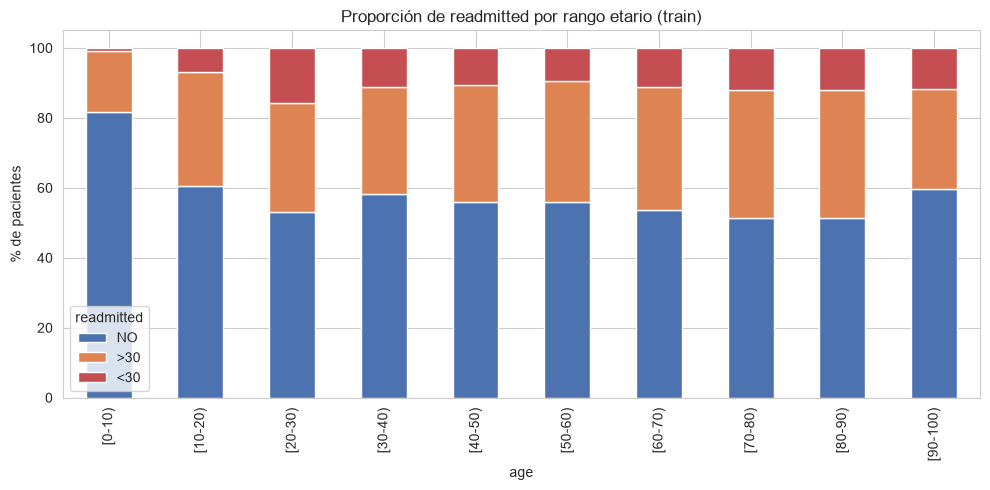

In [29]:
tabla_cruzada.plot(kind="bar", stacked=True, figsize=(10, 5),
                   color=["#4C72B0", "#DD8452", "#C44E52"])
plt.ylabel("% de pacientes")
plt.title("Proporción de readmitted por rango etario (train)")
plt.legend(title="readmitted")
plt.tight_layout()
plt.show()

**Por qué este gráfico:** barras apiladas (categórica ordinal × categórica nominal, para ver composición dentro de cada rango).

**Lectura.** El reingreso temprano no crece de forma pareja con la edad. Es casi nulo en menores de 10 años
(0,9 %), sube a 6,8 % entre los 10 y 20 años y alcanza el máximo de todo el dataset entre los 20 y 30 años
(15,7 %), por encima de cualquier grupo de adultos mayores. Después baja (9,4 % entre 50 y 60) y vuelve a subir de
a poco, hasta alrededor del 12 % después de los 70, sin recuperar el pico.

El pico en adultos jóvenes llama la atención, porque se suele asociar la edad avanzada con más riesgo. El
dataset no permite saber la causa, pero la bibliografía ofrece una hipótesis. Emons et al. (2016), con datos de
la misma base hospitalaria de la que proviene este dataset (Health Facts) y en pacientes internados por
hipoglucemia, encontraron que los adultos jóvenes tenían más riesgo de reingreso a 30 días aun ajustando por
otros factores, y lo atribuyeron a una menor adherencia al tratamiento y a la dieta. Con esa lectura, el
reingreso temprano de los jóvenes reflejaría más un problema de seguimiento que de gravedad clínica. Hay que
tomarlo con cautela: los menores de 30 son pocos (algo más de 1.800 internaciones en train), así que sus
porcentajes tienen más incertidumbre que los de los grupos mayores. 

#### `discharge_disposition_id` vs `readmitted`

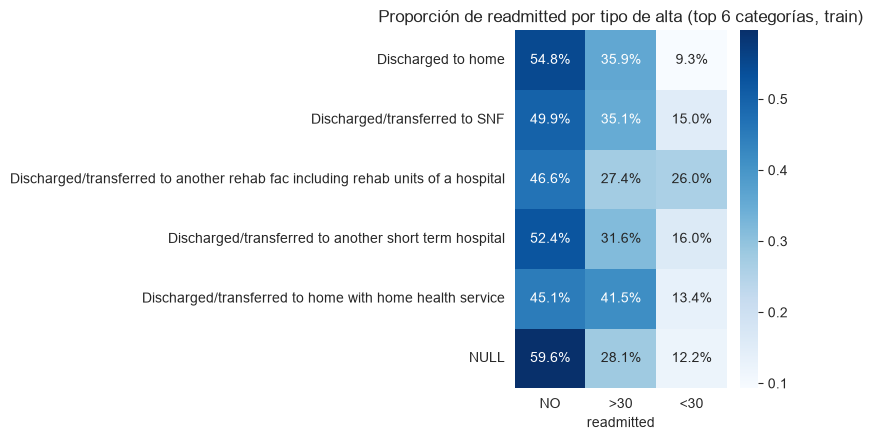

In [30]:
top_disposition = df_train["discharge_disposition_id"].value_counts().head(6).index
subset = df_train[df_train["discharge_disposition_id"].isin(top_disposition)].copy()

cross_tab_disp = pd.crosstab(subset["discharge_disposition_id"], subset["readmitted"],
                             normalize="index")
cross_tab_disp = cross_tab_disp.loc[cross_tab_disp.index.isin(top_disposition), ["NO", ">30", "<30"]]

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.heatmap(cross_tab_disp, annot=True, fmt=".1%", cmap="Blues", ax=ax)
ax.set_title("Proporción de readmitted por tipo de alta (top 6 categorías, train)")
ax.set_xlabel("readmitted"); ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Por qué este gráfico:** heatmap (categórica de cardinalidad media × categórica, para comparar muchas categorías de forma compacta).
El alta a domicilio es la que menos reingresos tempranos genera. Las altas con
seguimiento posterior tienen proporciones más altas, y la transferencia a **rehabilitación se
destaca claramente**, con varias veces la tasa del alta a domicilio. 

## 3.6 Medidas de asociación contra el target

Todas calculadas sobre train. Se elige la medida según el **par de tipos** involucrado

#### Chi-cuadrado de independencia y V de Cramér (categórica – categórica)

In [31]:
def chi2_cramers_v(col, target="readmitted", data=None):
    data = df_train if data is None else data
    tabla = pd.crosstab(data[col], data[target])
    chi2_stat, p, dof, _ = chi2_contingency(tabla)
    n = tabla.to_numpy().sum()
    k = min(tabla.shape) - 1
    v = np.sqrt(chi2_stat / (n * k)) if k > 0 else np.nan
    return chi2_stat, p, v

vars_categoricas_test = ["age", "gender", "race", "admission_type_id", "discharge_disposition_id",
                         "admission_source_id", "payer_code", "medical_specialty",
                         "diag_1", "diag_2", "diag_3", "A1Cresult", "max_glu_serum",
                         "insulin", "diabetesMed", "change"]

resultados = []
for c in vars_categoricas_test:
    chi2_stat, p, v = chi2_cramers_v(c)
    resultados.append([c, round(chi2_stat, 1), p, round(v, 3)])

cramer_target = (pd.DataFrame(resultados, columns=["variable", "chi2", "p_valor", "V_de_Cramer"])
                 .sort_values("V_de_Cramer", ascending=False)
                 .reset_index(drop=True))
cramer_target

,variable,chi2,p_valor,V_de_Cramer
0,discharge_disposition_id,2532.3,0.000000e+00,0.133
1,medical_specialty,833.8,9.988253e-101,0.107
2,admission_source_id,782.1,3.392260e-145,0.074
3,payer_code,375.5,3.076640e-60,0.066
4,diabetesMed,261.6,1.555116e-57,0.060
5,diag_1,440.1,3.921706e-82,0.055
6,insulin,392.4,1.184070e-81,0.052
7,change,161.3,9.403756e-36,0.047
8,admission_type_id,283.2,3.687357e-52,0.044
9,age,263.4,1.510369e-45,0.043


Con un tamaño muestral tan grande, prácticamente todas las variables dan
estadísticamente asociadas (p << 0.05), pero **el p-valor no dice nada sobre la fuerza**: para eso
está la V de Cramér. `discharge_disposition_id` se destaca claramente, seguida por
`admission_source_id`. `race`, `gender`, `A1Cresult` y `max_glu_serum` son las que menos
discriminan.

#### Coeficiente Phi (binaria – binaria)

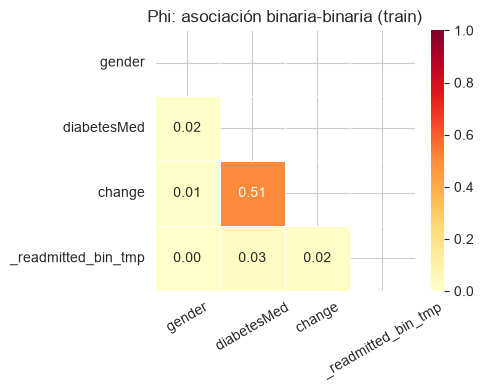

In [32]:
df_train["_readmitted_bin_tmp"] = (df_train["readmitted"] == "<30").astype(int)

def phi(x, y):
    tabla = pd.crosstab(x, y)
    chi2_stat = chi2_contingency(tabla)[0]
    n = tabla.to_numpy().sum()
    return np.sqrt(chi2_stat / n)

vars_binarias = ["gender", "diabetesMed", "change", "_readmitted_bin_tmp"]
phi_mat = pd.DataFrame(index=vars_binarias, columns=vars_binarias, dtype=float)
for c1 in vars_binarias:
    for c2 in vars_binarias:
        phi_mat.loc[c1, c2] = 1.0 if c1 == c2 else phi(df_train[c1], df_train[c2])

mask_upper = np.triu(np.ones_like(phi_mat, dtype=bool))
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(phi_mat.astype(float), annot=True, fmt=".2f", cmap="YlOrRd",
            vmin=0, vmax=1, linewidths=0.5, mask=mask_upper, ax=ax)
ax.set_title("Phi: asociación binaria-binaria (train)")
ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Lectura.** Ninguna variable binaria se asocia con el reingreso temprano (phi entre 0,00 y 0,03). La única
asociación apreciable es entre `diabetesMed` y `change` (0,51), esperable porque solo puede haber un cambio de
medicación si hay medicación. Es una redundancia que se resuelve en la sección 6.3.

#### Punto Biserial (numérica – binaria)

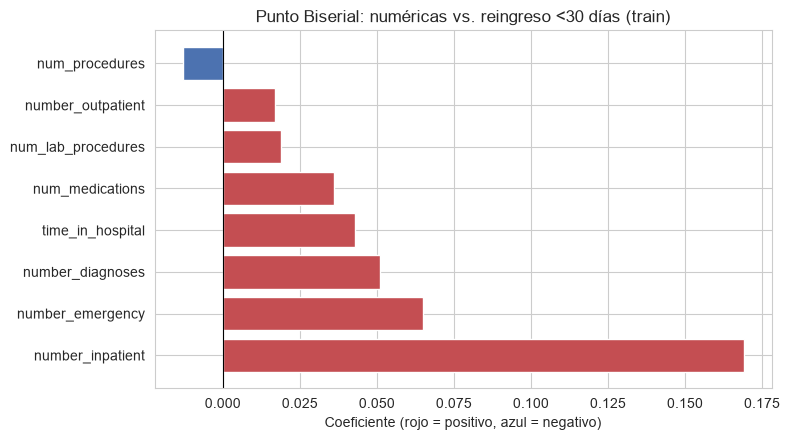

,variable,punto_biserial,p_valor
6,number_inpatient,0.169,0.000000e+00
5,number_emergency,0.065,1.196679e-68
7,number_diagnoses,0.051,6.448453e-42
0,time_in_hospital,0.043,4.837101e-30
3,num_medications,0.036,1.513032e-21
1,num_lab_procedures,0.019,4.973228e-07
4,number_outpatient,0.017,8.211182e-06
2,num_procedures,-0.013,3.135943e-04


In [33]:
resultados_pb = []
for col in cols_numericas:
    r, p = pointbiserialr(df_train["_readmitted_bin_tmp"], df_train[col])
    resultados_pb.append([col, round(r, 3), p])

pb_df = pd.DataFrame(resultados_pb, columns=["variable", "punto_biserial", "p_valor"])
pb_df = pb_df.sort_values("punto_biserial", key=abs, ascending=False)

fig, ax = plt.subplots(figsize=(8, 4.5))
colores = ["#C44E52" if v > 0 else "#4C72B0" for v in pb_df["punto_biserial"]]
ax.barh(pb_df["variable"], pb_df["punto_biserial"], color=colores)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Punto Biserial: numéricas vs. reingreso <30 días (train)")
ax.set_xlabel("Coeficiente (rojo = positivo, azul = negativo)")
plt.tight_layout()
plt.show()
pb_df

**Lectura.** `number_inpatient` se destaca con 0,169, más del doble que la siguiente (`number_emergency`, 0,065).
Las demás quedan por debajo de 0,06. Todos los p-valores son significativos por el tamaño de la muestra, pero la
magnitud muestra que, salvo las internaciones previas, cada variable numérica por sí sola dice muy poco del
reingreso temprano.

#### Kendall Tau-b (numérica – ordinal): `age` vs. numéricas

In [34]:
age_orden_local = list(df_train["age"].cat.categories)
age_codes = df_train["age"].map({cat: i for i, cat in enumerate(age_orden_local)})

resultados_tau = []
for col in cols_numericas:
    tau, p = kendalltau(age_codes, df_train[col], variant="b")
    resultados_tau.append([col, round(tau, 3), p])

pd.DataFrame(resultados_tau, columns=["variable", "kendall_tau_b", "p_valor"]) \
    .sort_values("kendall_tau_b", key=abs, ascending=False)

,variable,kendall_tau_b,p_valor
7,number_diagnoses,0.162,0.000000e+00
0,time_in_hospital,0.090,5.912821e-218
5,number_emergency,-0.057,1.035502e-67
2,num_procedures,-0.046,4.697923e-52
1,num_lab_procedures,0.022,9.588342e-16
4,number_outpatient,0.022,2.113731e-11
3,num_medications,0.019,3.924786e-12
6,number_inpatient,0.016,4.140835e-07


**Lectura.** La edad se asocia sobre todo con la cantidad de diagnósticos (0,162): los pacientes mayores acumulan
más diagnósticos registrados. Con el resto de las numéricas la asociación es muy débil (menor a 0,1), así que la
edad aporta información que no está contenida en las otras variables.

#### Eta cuadrado (numérica – categórica de 3 clases)

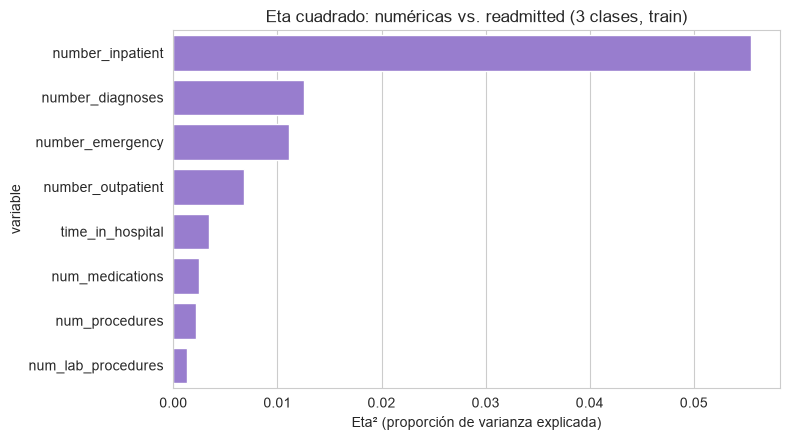

,variable,eta_cuadrado,p_valor
6,number_inpatient,0.0555,0.000000e+00
7,number_diagnoses,0.0126,1.852638e-197
5,number_emergency,0.0111,6.449392e-174
4,number_outpatient,0.0068,1.015036e-106
0,time_in_hospital,0.0034,9.638959e-54
3,num_medications,0.0025,1.738889e-39
2,num_procedures,0.0022,3.132795e-35
1,num_lab_procedures,0.0013,4.673295e-21


In [35]:
def eta_squared(continua, categorica):
    grupos = [g.to_numpy() for _, g in continua.groupby(categorica, observed=True)]
    F, p = f_oneway(*grupos)
    media_total = continua.mean()
    ss_total = ((continua - media_total) ** 2).sum()
    ss_between = sum(len(g) * (g.mean() - media_total) ** 2 for g in grupos)
    return ss_between / ss_total, p, F

resultados_eta = []
for col in cols_numericas:
    eta2v, p, F = eta_squared(df_train[col], df_train["readmitted"])
    resultados_eta.append([col, round(eta2v, 4), p])

eta_df = (pd.DataFrame(resultados_eta, columns=["variable", "eta_cuadrado", "p_valor"])
          .sort_values("eta_cuadrado", ascending=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(data=eta_df, y="variable", x="eta_cuadrado", color="mediumpurple", ax=ax)
ax.set_title("Eta cuadrado: numéricas vs. readmitted (3 clases, train)")
ax.set_xlabel("Eta² (proporción de varianza explicada)")
plt.tight_layout()
plt.show()
eta_df

Consistente con Punto Biserial, `number_inpatient` concentra la mayor proporción de
varianza explicada, seguido de `number_diagnoses` y `number_emergency`. Refuerza que **ninguna
variable aislada explica el reingreso**.

#### Distribución de numéricas por clase

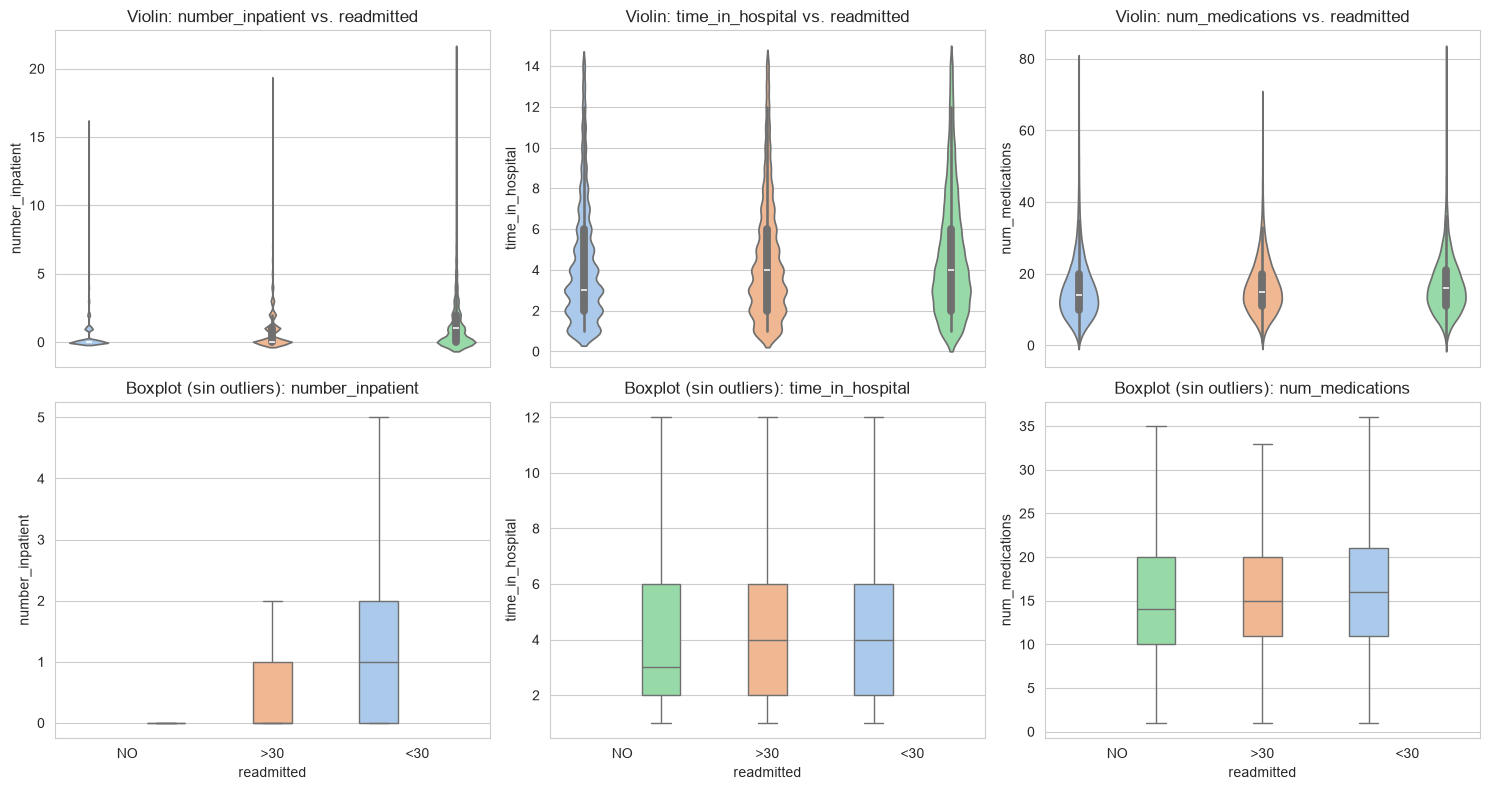

In [36]:
vars_a_graficar = ["number_inpatient", "time_in_hospital", "num_medications"]

fig, axes = plt.subplots(2, len(vars_a_graficar), figsize=(15, 8), sharex="col")
for j, col in enumerate(vars_a_graficar):
    sns.violinplot(data=df_train, x="readmitted", y=col, hue="readmitted",
                   order=["NO", ">30", "<30"], palette="pastel", legend=False, ax=axes[0, j])
    axes[0, j].set_title(f"Violin: {col} vs. readmitted")
    sns.boxplot(data=df_train, x="readmitted", y=col, hue="readmitted",
                order=["NO", ">30", "<30"], palette="pastel", legend=False,
                showfliers=False, ax=axes[1, j])
    axes[1, j].set_title(f"Boxplot (sin outliers): {col}")
plt.tight_layout()
plt.show()

**Lectura.** En las internaciones previas la diferencia entre clases es clara: la mediana es 0 en los pacientes
que no reingresan y 1 en los que reingresan antes de 30 días, cuya caja llega hasta 2. En el tiempo de
internación y en la cantidad de medicamentos las tres distribuciones casi se superponen, con medianas apenas
mayores entre los que reingresan (4 días contra 3, y 16 medicamentos contra 14). El gráfico confirma lo que
mostraron las medidas de asociación: la señal está en el historial del paciente más que en lo que pasó durante la
internación.

In [37]:
df_train = df_train.drop(columns=["_readmitted_bin_tmp"])

## 3.7 Correlación entre variables numéricas

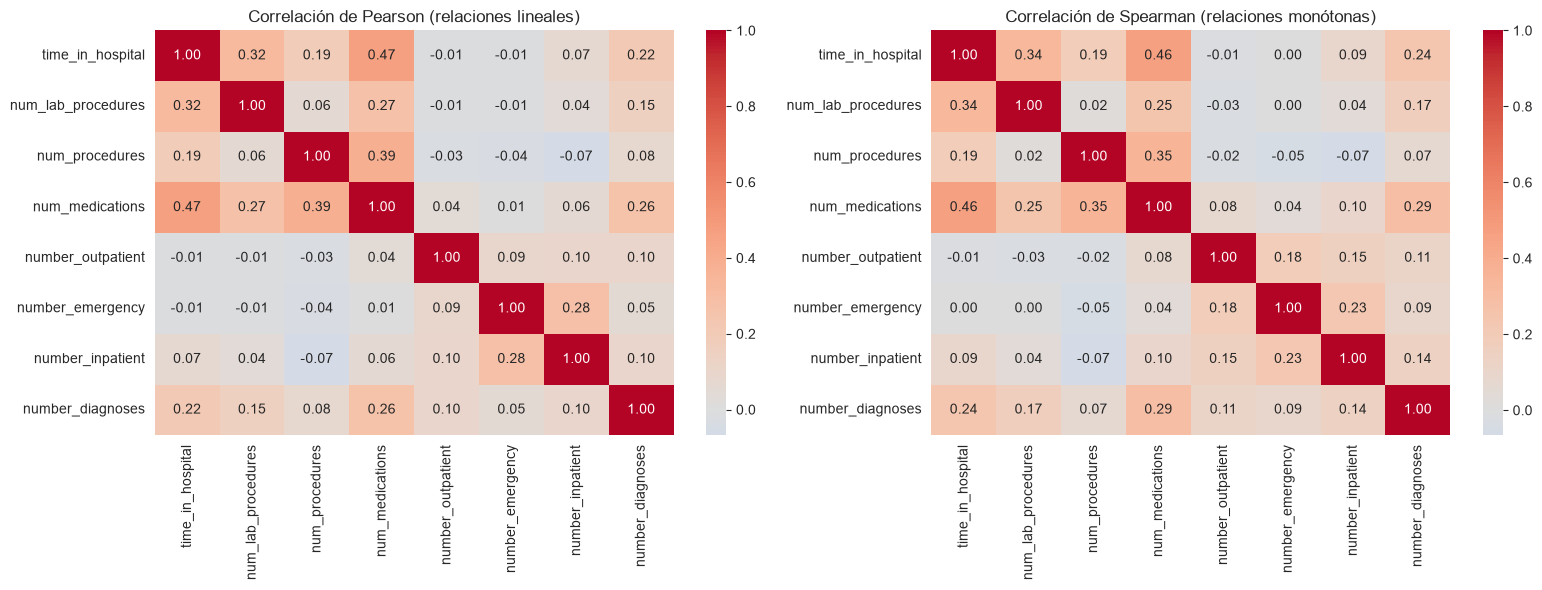

In [38]:
corr_pearson = df_train[cols_numericas].corr(method="pearson")
corr_spearman = df_train[cols_numericas].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0])
axes[0].set_title("Correlación de Pearson (relaciones lineales)")
sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Correlación de Spearman (relaciones monótonas)")
plt.tight_layout()
plt.show()

Se usan ambos coeficientes porque Pearson sólo capta relaciones lineales y varias de
estas variables (conteos muy asimétricos) tienen relaciones monótonas no lineales. En general las
correlaciones son bajas o moderadas (no hay multicolinealidad fuerte), salvo relaciones moderadas
esperables entre `num_medications` y `time_in_hospital`, `num_procedures` y `num_lab_procedures`.

**Interpretación consolidada de la sección 3:** el reingreso temprano es un fenómeno
**multifactorial** (ninguna variable aislada lo explica con fuerza), donde
`discharge_disposition_id` y el historial reciente de internaciones/urgencias
(`number_inpatient`, `number_emergency`) son las señales individuales más fuertes. Esto anticipa que
un modelo que combine varias variables debería superar a una regla simple basada en una sola, algo que
ponemos a prueba en los notebooks 2 a 4.

# 4. Preprocesamiento y limpieza

La limpieza general (eliminación de `gender` inválido) ya se hizo en 1.6, porque define el
universo del estudio y tenía que preceder al split. Queda el tratamiento de faltantes y de
outliers.

A partir de acá, **todo estadístico que se calcule sobre los datos** (moda para imputar, umbral de
winsorización, media/desvío de escalado) se obtiene **únicamente del conjunto de entrenamiento** y
se aplica igual sobre train y test.

## 4.1 Tratamiento de valores faltantes

Se decide qué hacer con cada variable identificada en 1.3. Para `race`, la única imputación que
depende de un estadístico calculado sobre los datos (la moda), se usa **únicamente la moda de
train**, aplicada igual sobre ambas particiones.

In [39]:
# --- weight: se elimina la columna (97% vacía = no aporta información explotable) ---
data_set = data_set.drop(columns=["weight"])

# --- max_glu_serum / A1Cresult: el faltante ES informacion (no se pidio el analisis).
#     Se agrega la categoria "No medido" (regla fija, no depende de train/test) ---
for c in ["max_glu_serum", "A1Cresult"]:
    data_set[c] = data_set[c].cat.add_categories(["No medido"]).fillna("No medido")
    orden_nuevo = ["No medido"] + [cat for cat in data_set[c].cat.categories if cat != "No medido"]
    data_set[c] = data_set[c].cat.reorder_categories(orden_nuevo, ordered=True)

# --- medical_specialty / payer_code: alta cardinalidad + muchos NaN -> categoria "Faltante" ---
for c in ["medical_specialty", "payer_code"]:
    data_set[c] = data_set[c].astype("object").fillna("Faltante").astype("category")

# --- race: baja proporcion de nulos, categorica nominal -> imputar con la MODA DE TRAIN ---
moda_race = data_set.loc[data_set["_es_train"], "race"].mode()[0]
data_set["race"] = data_set["race"].astype("object").fillna(moda_race).astype("category")
print("Moda de 'race' calculada SOLO con train:", moda_race)

# --- diag_1/2/3: muy pocos nulos -> categoria "Sin_diagnostico" (regla fija) ---
for c in ["diag_1", "diag_2", "diag_3"]:
    data_set[c] = data_set[c].astype("object").fillna("Sin_diagnostico").astype("category")

print("\nNulos restantes:", int(data_set.isnull().sum().sum()))
print("Nueva forma del dataset:", data_set.shape)

Moda de 'race' calculada SOLO con train: Caucasian

Nulos restantes: 0
Nueva forma del dataset: (101763, 51)


**Justificación general:** para variables numéricas se hubiera usado media/mediana según la
simetría de la distribución, pero en este dataset **todos los faltantes son categóricos**. Por eso
se optó por: (a) eliminar la columna cuando la pérdida de información es casi total (`weight`), o
(b) crear una categoría explícita de "faltante/no medido" cuando el hecho de que falte el dato es
en sí mismo informativo (que no se haya pedido A1C), evitando el sesgo de imputar con la moda en
variables de alta cardinalidad. La única imputación que usa un estadístico (`race`) se calculó
exclusivamente con train.

## 4.2 Detección y manejo de outliers

Siguiendo lo identificado en 3.2: no se eliminan outliers (son pacientes clínicamente relevantes),
pero se aplica **winsorización suave al percentil 99, calculado sólo con train**, para evitar que
valores extremos aislados distorsionen el escalado.

Nota de alcance: `number_emergency` y `number_inpatient` van además a discretizarse en 5.1 en
buckets `0/1/2/3 o más`, y son las versiones discretizadas las que entran al modelo. Para esas dos
la winsorización no tiene efecto sobre las features finales; sí lo tiene sobre
`num_lab_procedures` y `num_medications`, que entran al modelo como numéricas.

In [40]:
cols_winsor = ["num_lab_procedures", "number_emergency", "number_inpatient", "num_medications"]
for col in cols_winsor:
    p99 = data_set.loc[data_set["_es_train"], col].quantile(0.99)
    data_set[col] = np.where(data_set[col] > p99, p99, data_set[col])
    print(f"{col:22s} umbral p99 (train) = {p99}")

data_set[cols_winsor].describe().round(2)

num_lab_procedures     umbral p99 (train) = 85.0
number_emergency       umbral p99 (train) = 3.0
number_inpatient       umbral p99 (train) = 6.0
num_medications        umbral p99 (train) = 43.0


,num_lab_procedures,number_emergency,number_inpatient,num_medications
count,101763.00,101763.00,101763.00,101763.00
mean,43.04,0.16,0.62,15.94
std,19.53,0.53,1.14,7.80
min,1.00,0.00,0.00,1.00
25%,31.00,0.00,0.00,10.00
50%,44.00,0.00,0.00,15.00
75%,57.00,0.00,1.00,20.00
max,85.00,3.00,6.00,43.00


**Lectura.** El recorte al percentil 99 afecta a muy pocas filas: `num_lab_procedures` queda acotada en 85 (el
máximo era 132), `num_medications` en 43 (el máximo era 81), y los conteos de urgencias e internaciones previas en
3 y 6. La media prácticamente no cambia, que es lo que se busca: se acotan los extremos sin mover el centro de la
distribución.

#### Alternativa considerada: transformación logarítmica

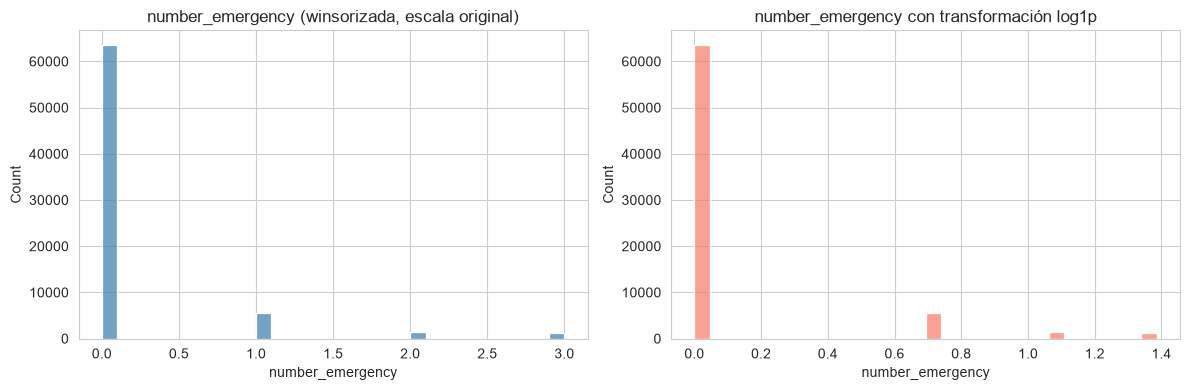

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data_set.loc[data_set["_es_train"], "number_emergency"], bins=30,
             ax=axes[0], color="steelblue")
axes[0].set_title("number_emergency (winsorizada, escala original)")
sns.histplot(np.log1p(data_set.loc[data_set["_es_train"], "number_emergency"]), bins=30,
             ax=axes[1], color="salmon")
axes[1].set_title("number_emergency con transformación log1p")
plt.tight_layout()
plt.show()

La transformación logarítmica comprime la cola, pero se **descarta**: (1) más del 90%
de los valores son 0, y `log1p` los sigue dejando en 0; (2) para los modelos candidatos la escala
no es tan crítica como para justificar la pérdida de interpretabilidad directa. Se mantiene la
winsorización y, en 5.1, la discretización.

# 5. Feature engineering

## 5.1 Nuevos features

### `patient_nbr_ordinal`: cantidad de encuentros previos por paciente

`patient_nbr` es un identificador sin orden real, así que no se usa directamente. En cambio se
deriva una variable con sentido clínico: la **cantidad de encuentros (internaciones) PREVIOS** que tuvo cada
paciente antes de la fila actual.

**Justificación:** un paciente con varios encuentros previos es, a priori, de mayor
complejidad/riesgo. Es importante contar sólo encuentros *previos* (no el total del paciente en
todo el dataset): usar el total incluiría encuentros *futuros* respecto de la fila actual, lo que
sería fuga temporal. Se usa `encounter_id` (estrictamente creciente dentro de cada paciente) como
proxy cronológico. El cálculo es **local a cada paciente**, y cada paciente cae entero en train o
en test (sección 2.2), así que no cruza información entre particiones.

In [42]:
data_set = data_set.sort_values(["patient_nbr", "encounter_id"]).reset_index(drop=True)
data_set["num_encuentros_previos"] = data_set.groupby("patient_nbr").cumcount()

def bucketizar(x):
    return str(x) if x <= 4 else "5 o mas"

orden_pnbr = ["0", "1", "2", "3", "4", "5 o mas"]
data_set["patient_nbr_ordinal"] = pd.Categorical(
    data_set["num_encuentros_previos"].apply(bucketizar), categories=orden_pnbr, ordered=True
)
data_set["patient_nbr_ordinal"].value_counts(normalize=True).reindex(orden_pnbr).mul(100).round(2)

patient_nbr_ordinal
0          70.28
1          16.48
2           6.23
3           2.96
4           1.56
5 o mas     2.49
Name: proportion, dtype: float64

### Familias farmacológicas

Las 23 columnas de medicamentos son difíciles de analizar por separado: la mayoría tiene muy poca
variabilidad. **Justificación:** se agrupan por familia farmacológica (clasificación médica
estándar) y se colapsa cada familia en una sola variable con la misma escala original (`No`,
`Steady`, `Up`, `Down`), pasando de 23 columnas dispersas a 6 variables manejables.

| Familia | Columnas que la integran |
|---|---|
| Biguanidas | `metformin` |
| Sulfonilureas | `chlorpropamide`, `glimepiride`, `acetohexamide`, `glipizide`, `glyburide`, `tolbutamide`, `tolazamide` |
| Meglitinidas | `repaglinide`, `nateglinide` |
| Glitazonas | `pioglitazone`, `rosiglitazone`, `troglitazone` |
| Alfa-glucosidasa | `acarbose`, `miglitol` |
| Insulina | `insulin` |

Las combinaciones de dos drogas aportan a las dos familias que combinan. `examide` y `citoglipton`
se excluyen (varianza cero). Cuando una familia tiene más de una droga informada para el mismo
paciente, se toma el estado de mayor intensidad (`Up > Down > Steady > No`).

In [43]:
mapa_familias = {
    "metformin": ["Biguanidas"], "repaglinide": ["Meglitinidas"], "nateglinide": ["Meglitinidas"],
    "chlorpropamide": ["Sulfonilureas"], "glimepiride": ["Sulfonilureas"], "acetohexamide": ["Sulfonilureas"],
    "glipizide": ["Sulfonilureas"], "glyburide": ["Sulfonilureas"], "tolbutamide": ["Sulfonilureas"],
    "pioglitazone": ["Glitazonas"], "rosiglitazone": ["Glitazonas"], "acarbose": ["Alfa_glucosidasa"],
    "miglitol": ["Alfa_glucosidasa"], "troglitazone": ["Glitazonas"], "tolazamide": ["Sulfonilureas"],
    "examide": [], "citoglipton": [], "insulin": ["Insulina"],
    "glyburide-metformin": ["Sulfonilureas", "Biguanidas"], "glipizide-metformin": ["Sulfonilureas", "Biguanidas"],
    "glimepiride-pioglitazone": ["Sulfonilureas", "Glitazonas"], "metformin-rosiglitazone": ["Biguanidas", "Glitazonas"],
    "metformin-pioglitazone": ["Biguanidas", "Glitazonas"],
}
familias = ["Biguanidas", "Sulfonilureas", "Meglitinidas", "Glitazonas", "Alfa_glucosidasa", "Insulina"]
prioridad = {"Up": 3, "Down": 2, "Steady": 1, "No": 0}

for familia in familias:
    cols_familia = [droga for droga, fams in mapa_familias.items() if familia in fams]
    nombre_col = f"familia_{familia.lower()}"
    data_set[nombre_col] = pd.Categorical(
        data_set[cols_familia].apply(lambda fila: max(fila, key=lambda v: prioridad.get(v, 0)), axis=1)
    )

cols_familias_nuevas = [f"familia_{f.lower()}" for f in familias]
resumen_familias = pd.DataFrame(
    {col: data_set[col].value_counts(normalize=True).round(3) for col in cols_familias_nuevas}
).fillna(0).T.reindex(columns=["No", "Steady", "Up", "Down"]).fillna(0)
resumen_familias

,No,Steady,Up,Down
familia_biguanidas,0.797,0.187,0.011,0.006
familia_sulfonilureas,0.716,0.253,0.019,0.013
familia_meglitinidas,0.978,0.020,0.001,0.001
familia_glitazonas,0.866,0.128,0.004,0.002
familia_alfa_glucosidasa,0.997,0.003,0.000,0.000
familia_insulina,0.466,0.303,0.111,0.120


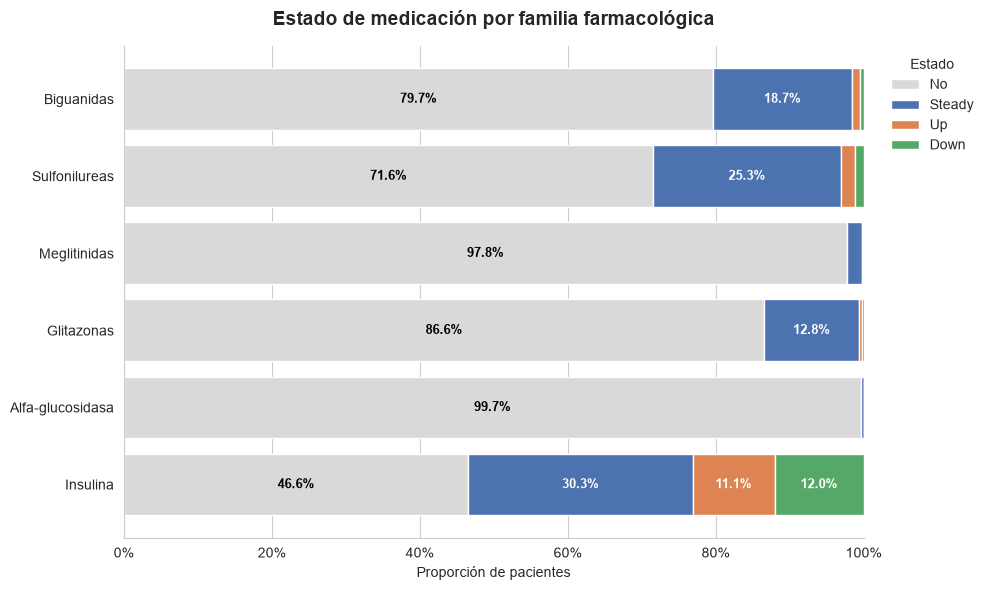

In [44]:
etiquetas_familias = {"familia_biguanidas": "Biguanidas", "familia_sulfonilureas": "Sulfonilureas",
                      "familia_meglitinidas": "Meglitinidas", "familia_glitazonas": "Glitazonas",
                      "familia_alfa_glucosidasa": "Alfa-glucosidasa", "familia_insulina": "Insulina"}
resumen_grafico = resumen_familias.rename(index=etiquetas_familias)
colores_estado = {"No": "#d9d9d9", "Steady": "#4C72B0", "Up": "#DD8452", "Down": "#55A868"}

fig, ax = plt.subplots(figsize=(10, 6))
izquierda = pd.Series(0.0, index=resumen_grafico.index)
for estado in ["No", "Steady", "Up", "Down"]:
    valores = resumen_grafico[estado]
    ax.barh(resumen_grafico.index, valores, left=izquierda, color=colores_estado[estado],
            label=estado, edgecolor="white")
    for i, (v, l) in enumerate(zip(valores, izquierda)):
        if v > 0.02:
            ax.text(l + v / 2, i, f"{v * 100:.1f}%", ha="center", va="center", fontsize=9,
                    color="white" if estado != "No" else "black", fontweight="bold")
    izquierda = izquierda + valores

ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(xmax=1))
ax.set_xlabel("Proporción de pacientes")
ax.set_title("Estado de medicación por familia farmacológica", fontsize=14, fontweight="bold", pad=15)
ax.legend(title="Estado", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
ax.invert_yaxis()
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.show()

**Lectura.** La insulina es la familia más usada y la única con cambios de dosis frecuentes: más de la mitad de
los pacientes la recibe, y en el 23 % la dosis se modificó (11,1 % aumentada y 12,0 % disminuida). Le siguen las
sulfonilureas y las biguanidas (metformina), casi siempre en dosis estable. Meglitinidas y alfa-glucosidasa casi
no se usan, lo que anticipa su baja relevancia en la selección de variables.

### Discretización de `number_emergency` / `number_inpatient`

**Justificación:** en 3.2 se vio que estas dos
variables tienen tanta masa puntual en 0 que el criterio IQR marca como "outlier" a cualquier valor
positivo. Ni la winsorización ni el `log1p` resuelven del todo el problema. La técnica más
apropiada es discretizarlas en una categórica ordinal con bins clínicos: `"0"`, `"1"`, `"2"`,
`"3 o más"`.

Los puntos de corte se definen **por criterio clínico, no por un cuantil calculado sobre los
datos**, así que no dependen de la partición. Esto es deliberado: usar cuantiles habría exigido
calcularlos sólo con train, agregando una dependencia innecesaria.

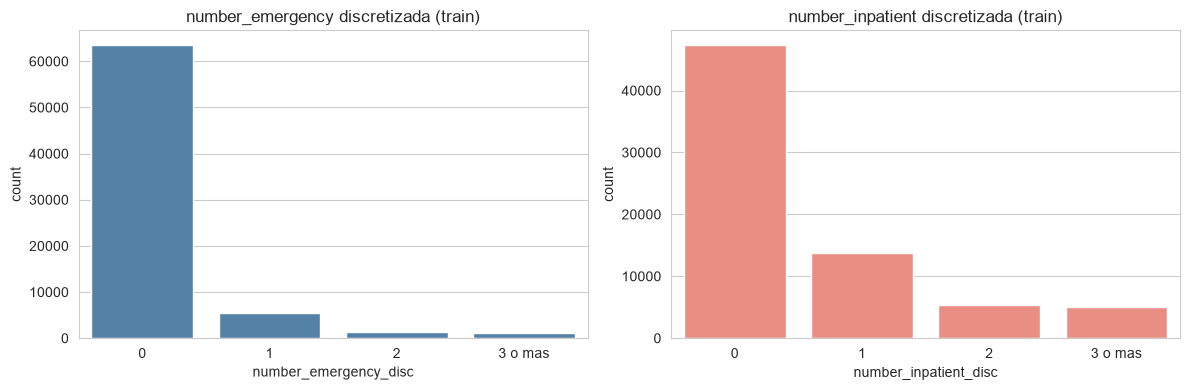

In [45]:
def discretizar_conteo(serie):
    def bin_conteo(x):
        if x == 0: return "0"
        elif x == 1: return "1"
        elif x == 2: return "2"
        else: return "3 o mas"
    return pd.Categorical(serie.apply(bin_conteo), categories=["0", "1", "2", "3 o mas"], ordered=True)

data_set["number_emergency_disc"] = discretizar_conteo(data_set["number_emergency"])
data_set["number_inpatient_disc"] = discretizar_conteo(data_set["number_inpatient"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=data_set.loc[data_set["_es_train"], "number_emergency_disc"],
              order=["0", "1", "2", "3 o mas"], ax=axes[0], color="steelblue")
axes[0].set_title("number_emergency discretizada (train)")
sns.countplot(x=data_set.loc[data_set["_es_train"], "number_inpatient_disc"],
              order=["0", "1", "2", "3 o mas"], ax=axes[1], color="salmon")
axes[1].set_title("number_inpatient discretizada (train)")
plt.tight_layout()
plt.show()

## 5.2 Separación de features (X) y target (y)

Se separan features y target reutilizando el split de la sección 2.2. **Todavía no se codifica
nada**: la codificación se aplica recién en la sección 7, y sólo sobre las variables que
sobrevivan a la selección de la sección 6.

In [46]:
id_cols = ["encounter_id", "patient_nbr"]
target_col = "readmitted_temprano"
cols_droga_individual = list(mapa_familias.keys())
drop_cols = id_cols + ["readmitted", target_col, "_es_train", "num_encuentros_previos"] + cols_droga_individual

X = data_set.drop(columns=drop_cols)
y = data_set[target_col]

mask_train = data_set["_es_train"].to_numpy()
X_train = X.loc[mask_train].reset_index(drop=True)
X_test = X.loc[~mask_train].reset_index(drop=True)
y_train_final = y.loc[mask_train].reset_index(drop=True)
y_test_final = y.loc[~mask_train].reset_index(drop=True)
y_train, y_test = y_train_final, y_test_final
grupos_train = data_set.loc[data_set["_es_train"], "patient_nbr"].reset_index(drop=True)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Proporción de clase positiva - train:", round(float(y_train_final.mean()), 3),
      " test:", round(float(y_test_final.mean()), 3))
print("\nVariables candidatas (sin codificar):", X_train.shape[1])

Train: (71583, 32)  Test: (30180, 32)
Proporción de clase positiva - train: 0.113  test: 0.109

Variables candidatas (sin codificar): 32


# 6. Reducción de dimensionalidad: selección de variables

**Momento del pipeline: después del split, antes de la codificación.** Es una decisión metodológica
nuestra y tiene tres consecuencias concretas:

1. **Chi² se calcula como corresponde.** Su definición es sobre una **tabla de contingencia** entre
   dos variables categóricas. Aplicado después del encoding termina corriendo
   sobre columnas de target encoding que son probabilidades en [0,1]: como "frecuencia", un valor
   de 0.13 no significa nada y el estadístico resultante no es interpretable. Sobre las variables
   originales, Chi² recupera su sentido estadístico.
2. **Se descartan variables, no columnas sueltas.** Seleccionar sobre la matriz codificada lleva a
   resultados incoherentes: quedarse con `payer_code_MC` y `payer_code_BC` pero descartar las otras
   16 dummies de la misma variable no es una decisión interpretable: no se puede explicar
   clínicamente ni implementar en producción (habría que pedir el dato completo igual). Acá la
   unidad de decisión es la variable.
3. **Se paga en granularidad.** Es el costo aceptado: si una variable tiene una sola categoría muy
   predictiva pero el resto es ruido, la medida agregada la puede subestimar y la variable entera
   cae. A cambio se gana un modelo con menos variables, más simple de explicar.

**Qué medida corresponde a cada tipo.** Esto es lo que obliga a hacerlo antes de codificar, porque
después del one-hot todas las columnas parecen numéricas y la distinción se pierde:

| Criterio | Se aplica a | Qué mide |
|---|---|---|
| **ANOVA F** (`f_classif`) | numéricas | Si la media de la variable difiere entre las clases del target |
| **Chi²** (`chi2_contingency`) | categóricas | Dependencia entre la variable y el target en la tabla de contingencia |
| **Información mutua** (`mutual_info_classif`) | **ambas** | Reducción de incertidumbre sobre el target; no asume forma de relación |

La información mutua es el único criterio que cruza los dos tipos, así que además de aportar su
propio ranking sirve como **denominador común** para comparar una numérica contra una categórica,
y como criterio de desempate cuando dos variables resultan redundantes entre sí (sección 6.2).

In [47]:
num_orig = [c for c in cols_numericas if c in X_train.columns]
cat_orig = [c for c in X_train.columns if str(X_train[c].dtype) == "category"]

print(f"Variables numéricas  ({len(num_orig)}): {num_orig}")
print()
print(f"Variables categóricas ({len(cat_orig)}):")
for c in cat_orig:
    print(f"   {c:26s} {X_train[c].nunique():3d} categorías")
print(f"\nTotal de variables candidatas: {len(num_orig) + len(cat_orig)}")

Variables numéricas  (8): ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses']

Variables categóricas (24):
   race                         5 categorías
   gender                       2 categorías
   age                         10 categorías
   admission_type_id            8 categorías
   discharge_disposition_id    26 categorías
   admission_source_id         16 categorías
   payer_code                  18 categorías
   medical_specialty           70 categorías
   diag_1                      11 categorías
   diag_2                      12 categorías
   diag_3                      12 categorías
   max_glu_serum                4 categorías
   A1Cresult                    4 categorías
   change                       2 categorías
   diabetesMed                  2 categorías
   patient_nbr_ordinal          6 categorías
   familia_biguanidas           4 categorías
   familia_sulfonil

## 6.1 Relevancia contra el target

### 6.1.1 ANOVA F: variables numéricas

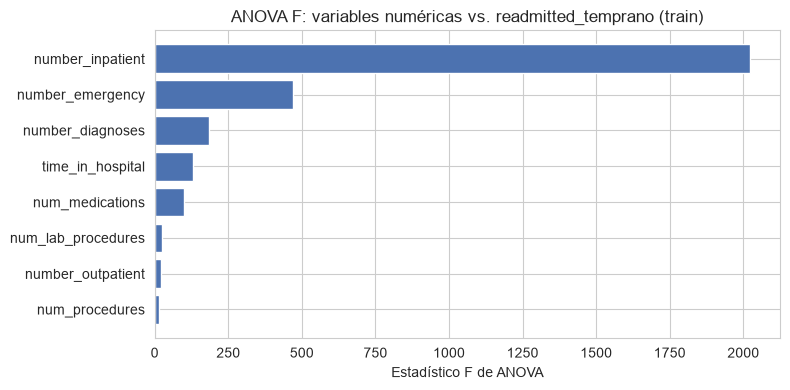

,variable,F,p_valor
0,number_inpatient,2023.4196,0.0000
1,number_emergency,469.1225,0.0000
2,number_diagnoses,184.2502,0.0000
3,time_in_hospital,129.7892,0.0000
4,num_medications,98.0593,0.0000
5,num_lab_procedures,26.0042,0.0000
6,number_outpatient,19.8910,0.0000
7,num_procedures,12.9887,0.0003


In [48]:
f_stat, p_val = f_classif(X_train[num_orig], y_train_final)
anova_df = (pd.DataFrame({"variable": num_orig, "F": f_stat, "p_valor": p_val})
            .sort_values("F", ascending=False).reset_index(drop=True))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(anova_df["variable"][::-1], anova_df["F"][::-1], color="#4C72B0")
ax.set_xlabel("Estadístico F de ANOVA")
ax.set_title("ANOVA F: variables numéricas vs. readmitted_temprano (train)")
plt.tight_layout()
plt.show()
anova_df.round(4)

`number_inpatient` domina ampliamente. Con 71.583 observaciones casi todos los
p-valores dan significativos, así que **el p-valor no sirve para ordenar**: lo que discrimina es la
magnitud del estadístico F. Es el mismo fenómeno que se vio en 3.6 con Chi²: con muestras grandes,
significancia estadística y relevancia práctica son cosas distintas.

### 6.1.2 Chi²: variables categóricas

Se calcula sobre la **tabla de contingencia** de cada variable contra el target. Se reporta también
la **V de Cramér**, que es el estadístico Chi² normalizado por el tamaño muestral y por la
cardinalidad: el Chi² crudo crece con el número de categorías, así que comparar directamente el
Chi² de `medical_specialty` (70 categorías) contra el de `gender` (2) favorecería a la primera por
un motivo puramente aritmético. **La V de Cramér es la que se usa para rankear**; el Chi² y su
p-valor quedan como el test de independencia propiamente dicho.

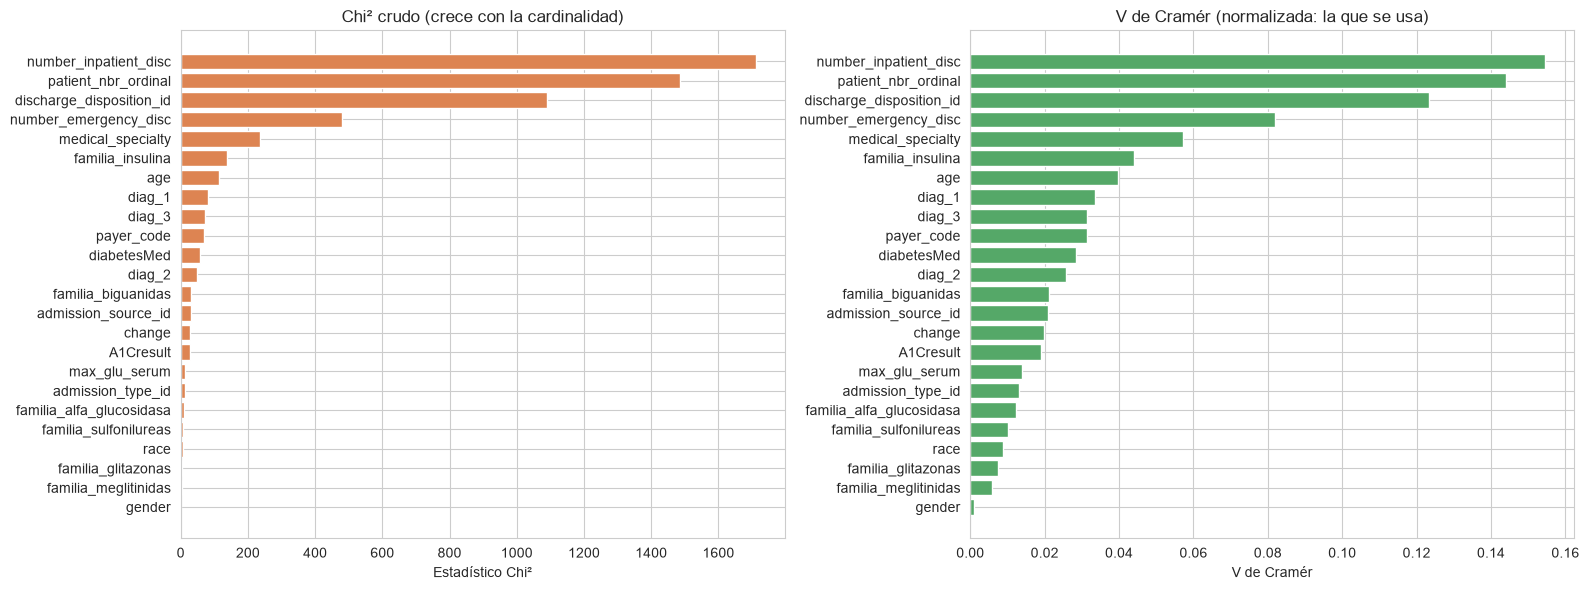

,variable,n_categorias,chi2,p_valor,V_de_Cramer
0,number_inpatient_disc,4,1711.2788,0.0000,0.1546
1,patient_nbr_ordinal,6,1485.9946,0.0000,0.1441
2,discharge_disposition_id,26,1088.9749,0.0000,0.1233
3,number_emergency_disc,4,481.0019,0.0000,0.0820
4,medical_specialty,70,235.0779,0.0000,0.0573
5,familia_insulina,4,139.0819,0.0000,0.0441
6,age,10,113.4993,0.0000,0.0398
7,diag_1,11,80.7637,0.0000,0.0336
8,diag_3,12,70.7671,0.0000,0.0314
9,payer_code,18,70.3277,0.0000,0.0313


In [49]:
filas_chi2 = []
for c in cat_orig:
    tabla = pd.crosstab(X_train[c], y_train_final)
    chi2_stat, p, dof, _ = chi2_contingency(tabla)
    n = tabla.to_numpy().sum()
    k = min(tabla.shape) - 1
    v = np.sqrt(chi2_stat / (n * k)) if k > 0 else np.nan
    filas_chi2.append([c, X_train[c].nunique(), chi2_stat, p, v])

chi2_df = (pd.DataFrame(filas_chi2, columns=["variable", "n_categorias", "chi2", "p_valor", "V_de_Cramer"])
           .sort_values("V_de_Cramer", ascending=False).reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(chi2_df["variable"][::-1], chi2_df["chi2"][::-1], color="#DD8452")
axes[0].set_xlabel("Estadístico Chi²"); axes[0].set_title("Chi² crudo (crece con la cardinalidad)")
axes[1].barh(chi2_df["variable"][::-1], chi2_df["V_de_Cramer"][::-1], color="#55A868")
axes[1].set_xlabel("V de Cramér"); axes[1].set_title("V de Cramér (normalizada: la que se usa)")
plt.tight_layout()
plt.show()
chi2_df.round(4)

La comparación de los dos gráficos muestra por qué hace falta normalizar.
`medical_specialty` y los `diag_*` suben en el Chi² crudo por tener muchas categorías, pero al
normalizar caen y `discharge_disposition_id` queda al frente con claridad. Todos los p-valores son
esencialmente 0, otra vez por el tamaño muestral.

### 6.1.3 Información mutua: todas las variables

Único criterio que aplica a los dos tipos a la vez. Se le indica cuáles variables son discretas
(las categóricas, pasadas a códigos enteros) para que use el estimador correcto en cada caso.

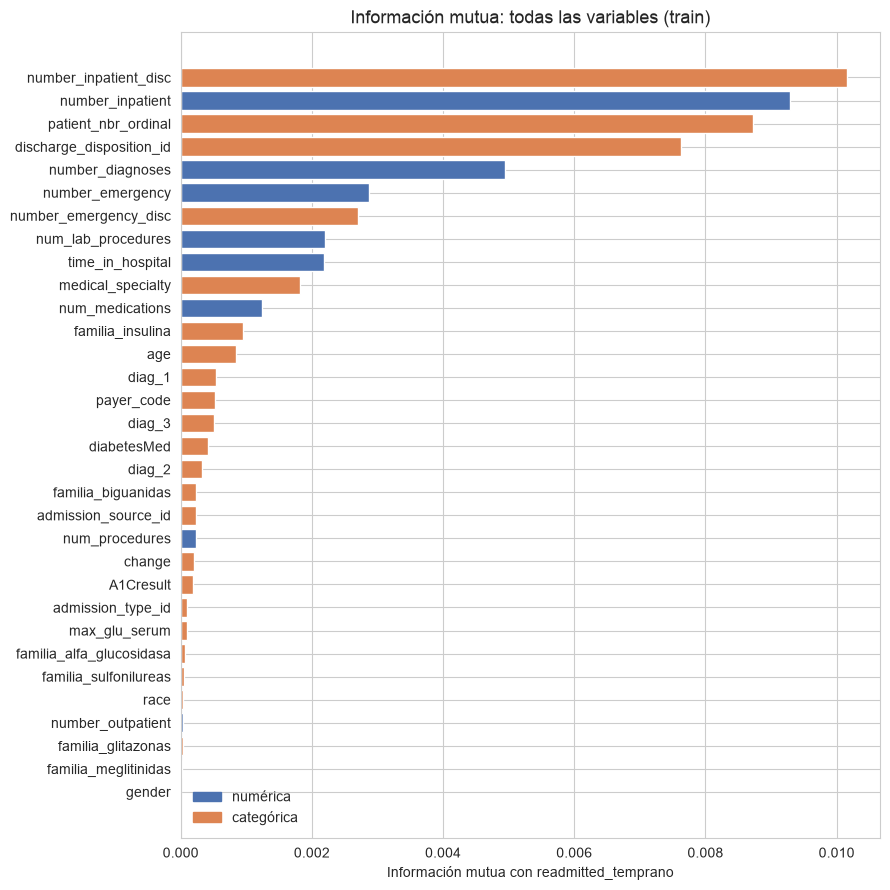

,variable,informacion_mutua,tipo
0,number_inpatient_disc,0.01015,categórica
1,number_inpatient,0.00929,numérica
2,patient_nbr_ordinal,0.00873,categórica
3,discharge_disposition_id,0.00763,categórica
4,number_diagnoses,0.00495,numérica
5,number_emergency,0.00287,numérica
6,number_emergency_disc,0.00271,categórica
7,num_lab_procedures,0.00221,numérica
8,time_in_hospital,0.00219,numérica
9,medical_specialty,0.00182,categórica


In [50]:
vars_mi = num_orig + cat_orig
X_mi = pd.DataFrame(index=X_train.index)
es_discreta_orig = []
for c in vars_mi:
    if c in cat_orig:
        X_mi[c] = X_train[c].cat.codes.astype(int)
        es_discreta_orig.append(True)
    else:
        X_mi[c] = X_train[c].astype(float)
        es_discreta_orig.append(False)

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    mi_scores = mutual_info_classif(X_mi, y_train_final,
                                    discrete_features=np.array(es_discreta_orig),
                                    random_state=RANDOM_STATE)

mi_df = (pd.DataFrame({"variable": vars_mi, "informacion_mutua": mi_scores,
                       "tipo": ["categórica" if c in cat_orig else "numérica" for c in vars_mi]})
         .sort_values("informacion_mutua", ascending=False).reset_index(drop=True))

MI_POR_VARIABLE = dict(zip(mi_df["variable"], mi_df["informacion_mutua"]))

fig, ax = plt.subplots(figsize=(9, 9))
colores = mi_df["tipo"].map({"numérica": "#4C72B0", "categórica": "#DD8452"})
ax.barh(mi_df["variable"][::-1], mi_df["informacion_mutua"][::-1], color=colores[::-1])
ax.set_xlabel("Información mutua con readmitted_temprano")
ax.set_title("Información mutua: todas las variables (train)", fontsize=13)
manijas = [plt.Rectangle((0, 0), 1, 1, color="#4C72B0"), plt.Rectangle((0, 0), 1, 1, color="#DD8452")]
ax.legend(manijas, ["numérica", "categórica"], frameon=False)
plt.tight_layout()
plt.show()
mi_df.head(15).round(5)

### 6.1.4 Tabla consolidada y criterio de descarte

Cada variable tiene **dos criterios aplicables**: la información mutua, y el que corresponde a su
tipo (ANOVA F si es numérica, V de Cramér si es categórica). Se convierten a **percentil dentro de
su grupo** para poder compararlos, donde 1.0 = la más relevante del grupo.

**Regla:** se descarta una variable sólo si queda en el **tercio inferior de los dos criterios a la
vez**. Es un criterio conservador a propósito: basta que un método la señale como relevante para
conservarla, porque cada uno tiene puntos ciegos distintos (ANOVA no capta relaciones no lineales,
la V de Cramér no aprovecha el orden de las ordinales, la información mutua es la más costosa de
estimar bien).

In [51]:
UMBRAL_PERCENTIL = 1 / 3

rel = pd.DataFrame({"variable": vars_mi})
rel["tipo"] = ["numérica" if c in num_orig else "categórica" for c in rel["variable"]]
rel["criterio_tipo"] = rel["variable"].map(
    {**dict(zip(anova_df["variable"], anova_df["F"])),
     **dict(zip(chi2_df["variable"], chi2_df["V_de_Cramer"]))})
rel["nombre_criterio"] = rel["tipo"].map({"numérica": "ANOVA F", "categórica": "V de Cramér"})
rel["info_mutua"] = rel["variable"].map(MI_POR_VARIABLE)

# percentil dentro del grupo de su tipo (1.0 = la mas relevante del grupo)
rel["pct_tipo"] = rel.groupby("tipo")["criterio_tipo"].rank(pct=True)
rel["pct_mi"] = rel.groupby("tipo")["info_mutua"].rank(pct=True)
rel["debil_en_ambos"] = (rel["pct_tipo"] <= UMBRAL_PERCENTIL) & (rel["pct_mi"] <= UMBRAL_PERCENTIL)

rel = rel.sort_values("pct_mi", ascending=False).reset_index(drop=True)
descartadas_relevancia = sorted(rel.loc[rel["debil_en_ambos"], "variable"])

print(f"Variables débiles en ambos criterios ({len(descartadas_relevancia)}):")
for v in descartadas_relevancia:
    fila = rel[rel["variable"] == v].iloc[0]
    print(f"  {v:26s} pct({fila['nombre_criterio']})={fila['pct_tipo']:.2f}  pct(MI)={fila['pct_mi']:.2f}")

rel[["variable", "tipo", "nombre_criterio", "criterio_tipo", "info_mutua",
     "pct_tipo", "pct_mi", "debil_en_ambos"]].round(4)

Variables débiles en ambos criterios (10):
  admission_type_id          pct(V de Cramér)=0.29  pct(MI)=0.33
  familia_alfa_glucosidasa   pct(V de Cramér)=0.25  pct(MI)=0.25
  familia_glitazonas         pct(V de Cramér)=0.12  pct(MI)=0.12
  familia_meglitinidas       pct(V de Cramér)=0.08  pct(MI)=0.08
  familia_sulfonilureas      pct(V de Cramér)=0.21  pct(MI)=0.21
  gender                     pct(V de Cramér)=0.04  pct(MI)=0.04
  max_glu_serum              pct(V de Cramér)=0.33  pct(MI)=0.29
  num_procedures             pct(ANOVA F)=0.12  pct(MI)=0.25
  number_outpatient          pct(ANOVA F)=0.25  pct(MI)=0.12
  race                       pct(V de Cramér)=0.17  pct(MI)=0.17


,variable,tipo,nombre_criterio,criterio_tipo,info_mutua,pct_tipo,pct_mi,debil_en_ambos
0,number_inpatient_disc,categórica,V de Cramér,0.1546,0.0102,1.0000,1.0000,False
1,number_inpatient,numérica,ANOVA F,2023.4196,0.0093,1.0000,1.0000,False
2,patient_nbr_ordinal,categórica,V de Cramér,0.1441,0.0087,0.9583,0.9583,False
3,discharge_disposition_id,categórica,V de Cramér,0.1233,0.0076,0.9167,0.9167,False
4,number_emergency_disc,categórica,V de Cramér,0.0820,0.0027,0.8750,0.8750,False
5,number_diagnoses,numérica,ANOVA F,184.2502,0.0049,0.7500,0.8750,False
6,medical_specialty,categórica,V de Cramér,0.0573,0.0018,0.8333,0.8333,False
7,familia_insulina,categórica,V de Cramér,0.0441,0.0009,0.7917,0.7917,False
8,age,categórica,V de Cramér,0.0398,0.0009,0.7500,0.7500,False
9,number_emergency,numérica,ANOVA F,469.1225,0.0029,0.8750,0.7500,False


#### Comparación normalizada de los tres métodos

Para leer los tres criterios en una misma escala, normalizamos cada uno a [0, 1]. La información mutua es la
única columna completa, porque es el único criterio que se aplica a numéricas y categóricas a la vez, y por eso
es la que permite compararlas entre sí.

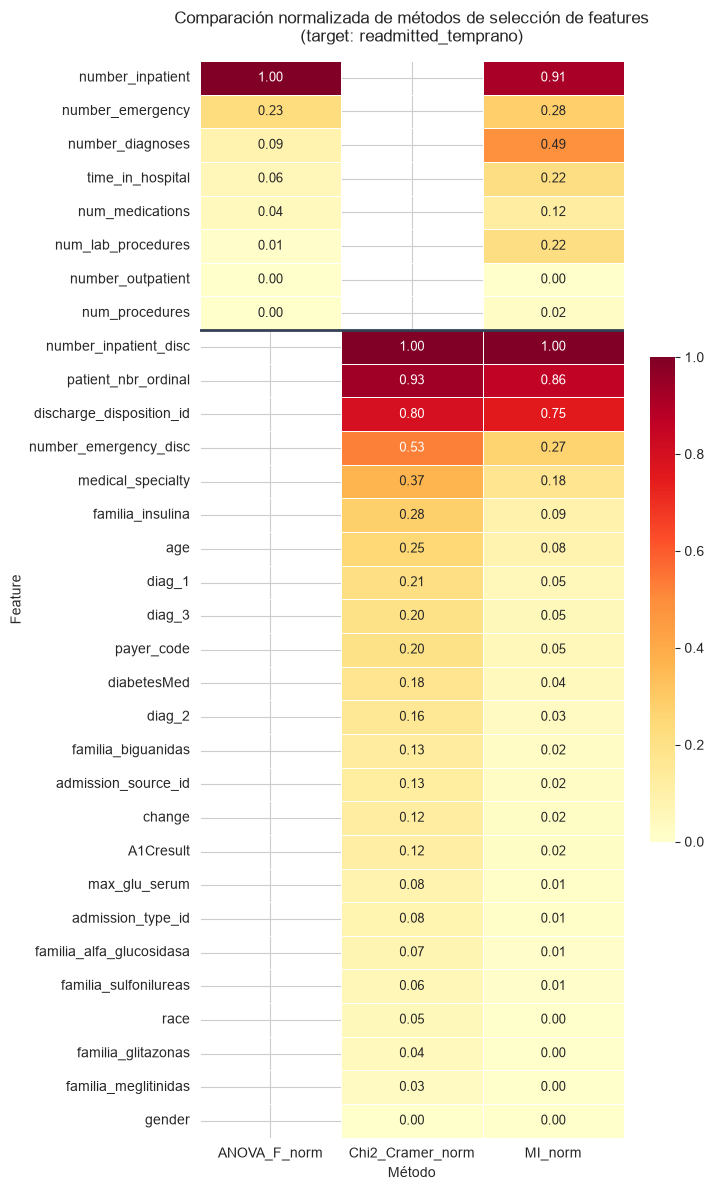

In [52]:
comp = rel.set_index("variable").copy()
es_num = comp["tipo"] == "numérica"

heat = pd.DataFrame(index=comp.index, dtype=float,
                    columns=["ANOVA_F_norm", "Chi2_Cramer_norm", "MI_norm"])
heat.loc[es_num, "ANOVA_F_norm"] = MinMaxScaler().fit_transform(
    comp.loc[es_num, ["criterio_tipo"]]).flatten()
heat.loc[~es_num, "Chi2_Cramer_norm"] = MinMaxScaler().fit_transform(
    comp.loc[~es_num, ["criterio_tipo"]]).flatten()
heat["MI_norm"] = MinMaxScaler().fit_transform(comp[["info_mutua"]]).flatten()

# Bloque de numericas arriba y de categoricas abajo, cada uno ordenado por su propio criterio
orden = (list(comp[es_num].sort_values("criterio_tipo", ascending=False).index)
         + list(comp[~es_num].sort_values("criterio_tipo", ascending=False).index))
heat = heat.loc[orden]

fig, ax = plt.subplots(figsize=(7.5, 12))
sns.heatmap(heat, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1,
            linewidths=0.6, linecolor="white", annot_kws={"size": 9},
            cbar_kws={"shrink": 0.45}, ax=ax)
ax.axhline(int(es_num.sum()), color="#334155", lw=2)   # separa numericas de categoricas
ax.set_title("Comparación normalizada de métodos de selección de features\n"
             "(target: readmitted_temprano)", fontsize=12, pad=14)
ax.set_xlabel("Método"); ax.set_ylabel("Feature")
plt.tight_layout()
plt.show()

Las variables que encabezan los dos bloques son las mismas que lideran la
información mutua, así que los tres métodos coinciden en lo grueso. Donde discrepan es
informativo: una variable con ANOVA F alto pero información mutua baja tiene una relación
**lineal** con el target que la información mutua no premia especialmente, y a la inversa,
una con información mutua alta y criterio de tipo bajo sugiere una relación **no lineal o no
monótona** que ANOVA no captura. Por eso la regla de descarte exige que sea débil en los dos
a la vez, y no en uno solo.

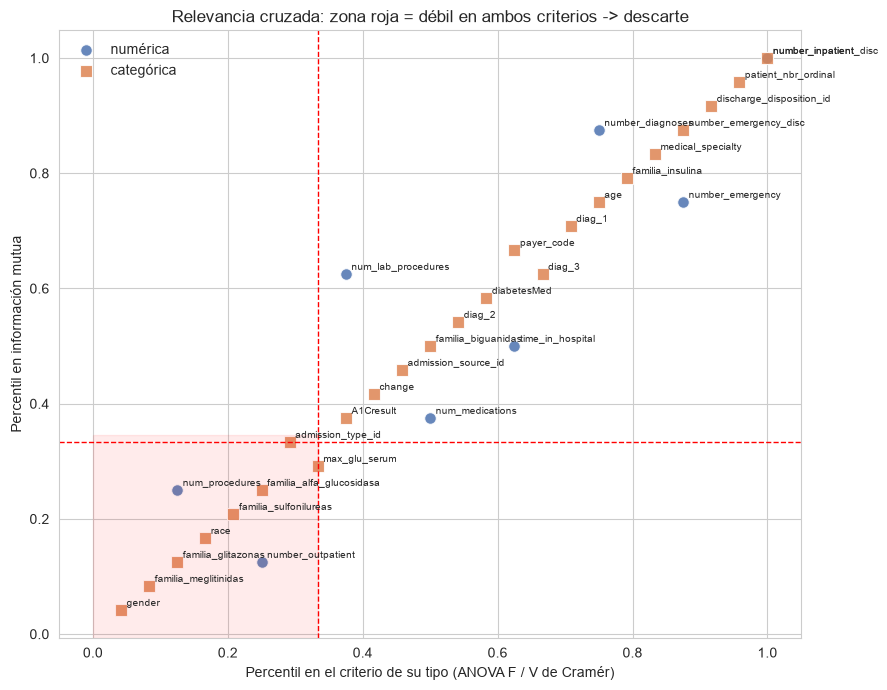

In [53]:
fig, ax = plt.subplots(figsize=(9, 7))
for tipo, marcador, color in [("numérica", "o", "#4C72B0"), ("categórica", "s", "#DD8452")]:
    sub = rel[rel["tipo"] == tipo]
    ax.scatter(sub["pct_tipo"], sub["pct_mi"], marker=marcador, s=70, color=color,
               label=tipo, alpha=0.85, edgecolor="white", linewidth=0.8)
for _, f in rel.iterrows():
    ax.annotate(f["variable"], (f["pct_tipo"], f["pct_mi"]), fontsize=7,
                xytext=(4, 3), textcoords="offset points")
ax.axvspan(0, UMBRAL_PERCENTIL, ymin=0, ymax=UMBRAL_PERCENTIL, color="red", alpha=0.08)
ax.axvline(UMBRAL_PERCENTIL, color="red", ls="--", lw=1)
ax.axhline(UMBRAL_PERCENTIL, color="red", ls="--", lw=1)
ax.set_xlabel("Percentil en el criterio de su tipo (ANOVA F / V de Cramér)")
ax.set_ylabel("Percentil en información mutua")
ax.set_title("Relevancia cruzada: zona roja = débil en ambos criterios -> descarte", fontsize=12)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

El gráfico hace visible el grado de acuerdo entre criterios. Los puntos alineados
sobre la diagonal son variables donde ambos métodos coinciden; los que se despegan son los casos
interesantes, típicamente variables con relación **no lineal** con el target, que la información
mutua detecta y ANOVA subestima. Sólo caen las que quedan en el cuadrante rojo inferior izquierdo.

## 6.2 Evaluación de relaciones entre variables (redundancia)

Ya medida la relevancia, se evalúa la redundancia **entre** features: dos variables muy asociadas
entre sí aportan información solapada, y conviene quedarse con una. La medida correcta depende otra
vez del par de tipos.

### 6.2.1 Numérica ↔ numérica: Pearson, Spearman y VIF

Se usan **los dos coeficientes** porque Pearson sólo capta relaciones lineales y varias de estas
variables son conteos muy asimétricos, donde la relación puede ser monótona pero no lineal.

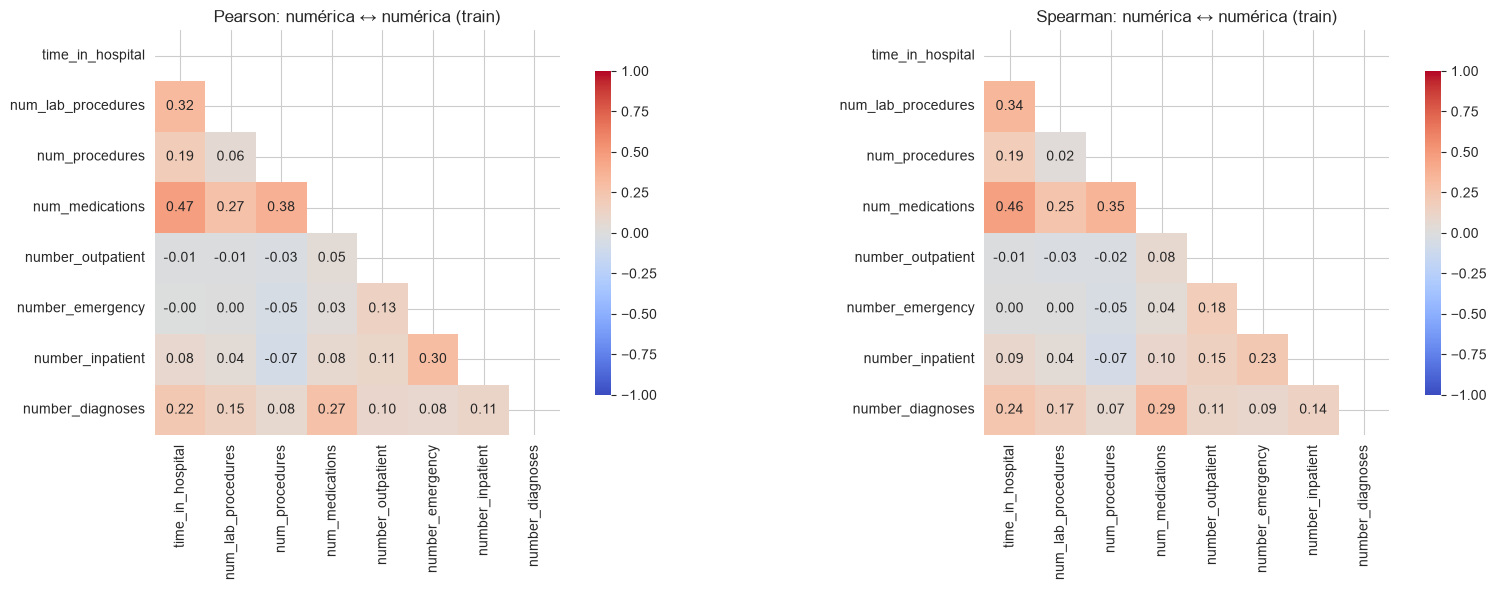

Máxima |Pearson|  entre numéricas: 0.470
Máxima |Spearman| entre numéricas: 0.465
Pares por encima del umbral de 0.7: 0


In [54]:
corr_p = X_train[num_orig].corr(method="pearson")
corr_s = X_train[num_orig].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
mask = np.triu(np.ones_like(corr_p, dtype=bool))
sns.heatmap(corr_p, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, ax=axes[0], cbar_kws={"shrink": .8})
axes[0].set_title("Pearson: numérica ↔ numérica (train)")
sns.heatmap(corr_s, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, square=True, ax=axes[1], cbar_kws={"shrink": .8})
axes[1].set_title("Spearman: numérica ↔ numérica (train)")
plt.tight_layout()
plt.show()

UMBRAL_NUM = 0.7
maxp = corr_p.where(np.triu(np.ones(corr_p.shape), k=1).astype(bool)).abs().max().max()
maxs = corr_s.where(np.triu(np.ones(corr_s.shape), k=1).astype(bool)).abs().max().max()
print(f"Máxima |Pearson|  entre numéricas: {maxp:.3f}")
print(f"Máxima |Spearman| entre numéricas: {maxs:.3f}")
print(f"Pares por encima del umbral de {UMBRAL_NUM}: "
      f"{int((corr_p.where(np.triu(np.ones(corr_p.shape), k=1).astype(bool)).abs() >= UMBRAL_NUM).sum().sum())}")

La correlación de a pares no detecta la multicolinealidad **múltiple**: una variable puede ser
predecible a partir de la combinación de otras tres sin correlacionar fuerte con ninguna en
particular. El **VIF** sí lo detecta, porque regresa cada variable contra todas las demás. Regla
práctica: VIF > 5 sospechoso, VIF > 10 multicolinealidad seria.

In [55]:
X_vif = sm.add_constant(X_train[num_orig].astype(float))
vif_df = pd.DataFrame({
    "variable": X_vif.columns,
    "VIF": [variance_inflation_factor(X_vif.to_numpy(), i) for i in range(X_vif.shape[1])],
})
vif_df = vif_df[vif_df["variable"] != "const"].sort_values("VIF", ascending=False).reset_index(drop=True)
vif_df["diagnostico"] = pd.cut(vif_df["VIF"], bins=[0, 5, 10, np.inf],
                               labels=["OK", "sospechoso (>5)", "serio (>10)"])
vif_df.round(2)

,variable,VIF,diagnostico
0,num_medications,1.54,OK
1,time_in_hospital,1.37,OK
2,num_procedures,1.19,OK
3,num_lab_procedures,1.14,OK
4,number_inpatient,1.13,OK
5,number_emergency,1.12,OK
6,number_diagnoses,1.12,OK
7,number_outpatient,1.03,OK


### 6.2.2 Categórica ↔ categórica: V de Cramér

Para dos categóricas no aplica la correlación: la medida correcta es la **V de Cramér**, la misma
que se usó contra el target en 6.1.2, ahora entre pares de features.

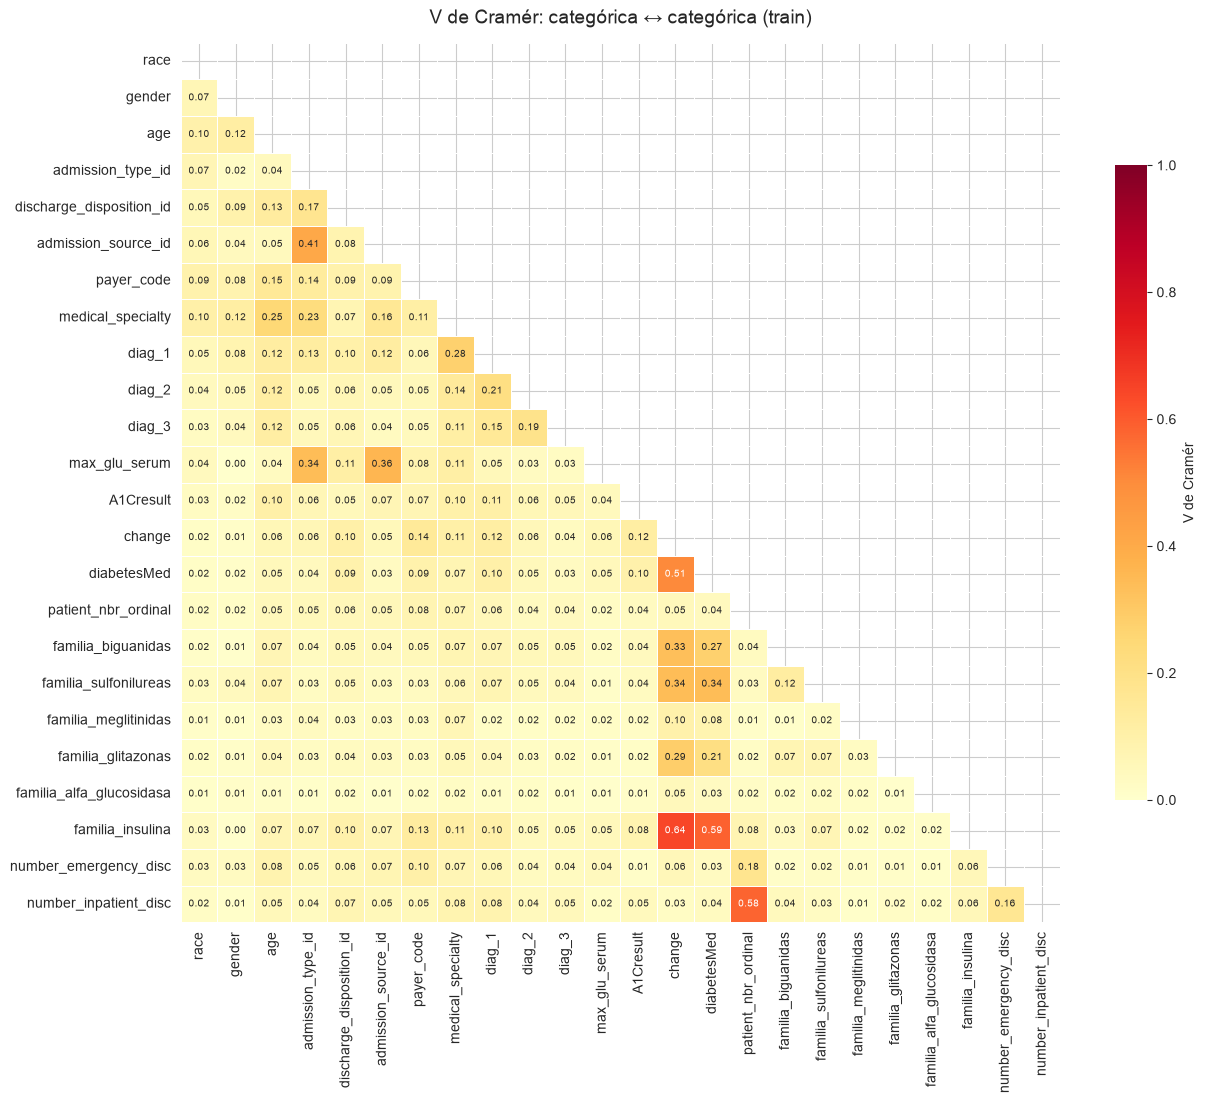

In [56]:
def cramers_v(x, y_):
    tabla = pd.crosstab(x, y_)
    if tabla.shape[0] < 2 or tabla.shape[1] < 2:
        return np.nan
    chi2_stat = chi2_contingency(tabla)[0]
    n = tabla.to_numpy().sum()
    k = min(tabla.shape) - 1
    return np.sqrt(chi2_stat / (n * k))

cramer_mat = pd.DataFrame(np.eye(len(cat_orig)), index=cat_orig, columns=cat_orig)
for i, c1 in enumerate(cat_orig):
    for c2 in cat_orig[i + 1:]:
        v = cramers_v(X_train[c1], X_train[c2])
        cramer_mat.loc[c1, c2] = v
        cramer_mat.loc[c2, c1] = v

fig, ax = plt.subplots(figsize=(13, 11))
mask = np.triu(np.ones_like(cramer_mat, dtype=bool))
sns.heatmap(cramer_mat, mask=mask, annot=True, fmt=".2f", cmap="YlOrRd", vmin=0, vmax=1,
            square=True, linewidths=0.4, ax=ax, annot_kws={"size": 7},
            cbar_kws={"label": "V de Cramér", "shrink": .7})
ax.set_title("V de Cramér: categórica ↔ categórica (train)", fontsize=14, pad=14)
plt.tight_layout()
plt.show()

In [57]:
UMBRAL_CAT = 0.5
vm = cramer_mat.where(np.triu(np.ones(cramer_mat.shape), k=1).astype(bool)).stack()
pares_cat = (pd.DataFrame({"feature_1": [i[0] for i in vm.index],
                           "feature_2": [i[1] for i in vm.index],
                           "V_de_Cramer": vm.to_numpy().round(3)})
             .sort_values("V_de_Cramer", ascending=False).reset_index(drop=True))
print(f"Pares categóricos con V >= {UMBRAL_CAT}: {(pares_cat['V_de_Cramer'] >= UMBRAL_CAT).sum()}\n")
pares_cat.head(12)

Pares categóricos con V >= 0.5: 4



,feature_1,feature_2,V_de_Cramer
0,change,familia_insulina,0.643
1,diabetesMed,familia_insulina,0.587
2,patient_nbr_ordinal,number_inpatient_disc,0.580
3,change,diabetesMed,0.506
4,admission_type_id,admission_source_id,0.409
5,admission_source_id,max_glu_serum,0.363
6,diabetesMed,familia_sulfonilureas,0.343
7,admission_type_id,max_glu_serum,0.341
8,change,familia_sulfonilureas,0.341
9,change,familia_biguanidas,0.333


**Lectura.** Las asociaciones fuertes entre variables categóricas son pocas y tienen explicación: `change` y
`diabetesMed` con la familia de la insulina (0,64 y 0,59), porque la insulina es la medicación que más se
modifica; las internaciones previas y los encuentros previos del paciente (0,58), que miden el historial con
ventanas de tiempo distintas; y `change` con `diabetesMed` (0,51). El resto queda por debajo de 0,45. Qué se hace
con cada par se decide en la sección 6.3.

### 6.2.3 Numérica ↔ categórica: Eta cuadrado

Completa la grilla de tipos. El **Eta cuadrado** (razón de correlación) es la proporción de varianza
de la numérica explicada por la pertenencia a cada categoría: 0 = la categórica no dice nada sobre
la numérica, 1 = la determina completamente.

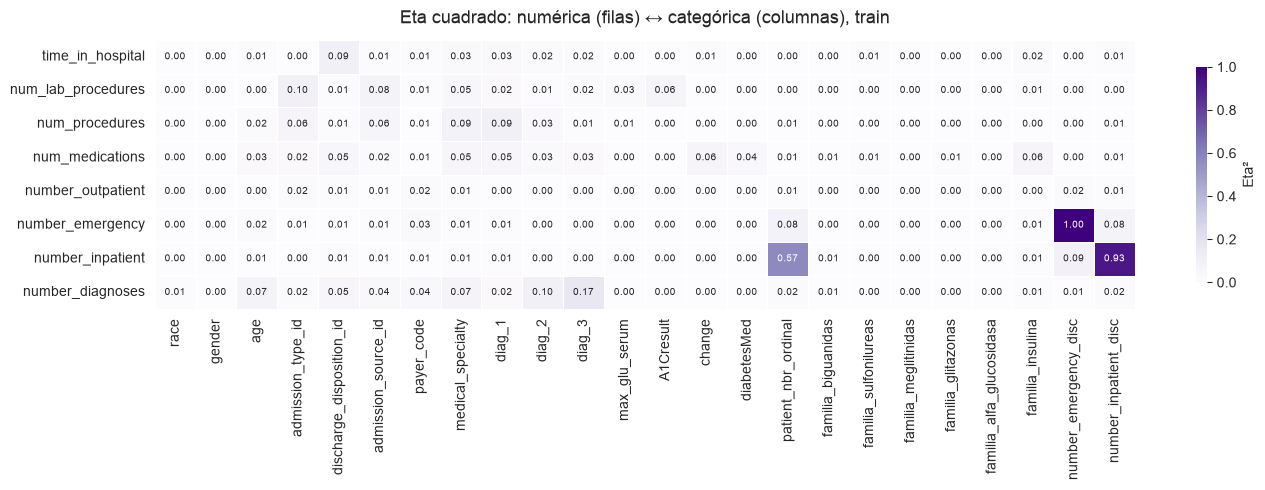

,numerica,categorica,eta_cuadrado
0,number_emergency,number_emergency_disc,1.000
1,number_inpatient,number_inpatient_disc,0.929
2,number_inpatient,patient_nbr_ordinal,0.567
3,number_diagnoses,diag_3,0.166
4,number_diagnoses,diag_2,0.101
5,num_lab_procedures,admission_type_id,0.101
6,num_procedures,diag_1,0.095
7,time_in_hospital,discharge_disposition_id,0.095


In [58]:
def eta2_num_cat(num, cat):
    grupos = [g.to_numpy() for _, g in num.groupby(cat, observed=True) if len(g) > 0]
    if len(grupos) < 2:
        return np.nan
    media_total = num.mean()
    ss_total = ((num - media_total) ** 2).sum()
    ss_between = sum(len(g) * (g.mean() - media_total) ** 2 for g in grupos)
    return ss_between / ss_total if ss_total > 0 else np.nan

eta_mat = pd.DataFrame(index=num_orig, columns=cat_orig, dtype=float)
for n_ in num_orig:
    for c in cat_orig:
        eta_mat.loc[n_, c] = eta2_num_cat(X_train[n_], X_train[c])

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(eta_mat.astype(float), annot=True, fmt=".2f", cmap="Purples", vmin=0, vmax=1,
            linewidths=0.4, ax=ax, annot_kws={"size": 7}, cbar_kws={"label": "Eta²", "shrink": .8})
ax.set_title("Eta cuadrado: numérica (filas) ↔ categórica (columnas), train", fontsize=13, pad=12)
plt.tight_layout()
plt.show()

em = eta_mat.stack().sort_values(ascending=False)
pares_mixtos = pd.DataFrame({"numerica": [i[0] for i in em.index],
                             "categorica": [i[1] for i in em.index],
                             "eta_cuadrado": em.to_numpy().round(3)})
pares_mixtos.head(8)

**Lectura del bloque mixto:** los valores más altos son los pares donde la categórica es la
**versión discretizada** de la propia numérica (`number_emergency` ↔ `number_emergency_disc`,
`number_inpatient` ↔ `number_inpatient_disc`). Es redundancia por construcción y ya está resuelta
por diseño: el ensamblado de la sección 7 usa la versión discretizada y deja fuera la numérica
cruda, en vez de meter las dos. Fuera de esos pares, ninguna categórica explica una porción
sustancial de la varianza de una numérica.

## 6.3 Decisión final: variables descartadas y conservadas

Se combinan los dos análisis. Para la redundancia categórica se aplican **dos niveles**, con la
información mutua de 6.1.3 como criterio de desempate:

1. **V ≥ 0.7: descarte automático.** Las dos variables son prácticamente la misma; se conserva la
   de mayor información mutua con el target.
2. **0.5 ≤ V < 0.7: decisión explícita.** La asociación es fuerte pero las variables no son
   intercambiables. Se descarta sólo si una está **conceptualmente contenida** en la otra.

Aplicado a este dataset:

- **Se descartan `change` y `diabetesMed`**: son resúmenes binarios de lo que las seis variables de
  familia farmacológica ya expresan con cuatro estados (`Up`/`Down` **es** un cambio de medicación;
  `No` vs. el resto **es** el "hay medicación"). Además su información mutua con el target está
  entre las más bajas, así que la pérdida es mínima.
- **Se conservan `patient_nbr_ordinal` y `number_inpatient_disc`** pese a su V de 0.58: miden
  **ventanas temporales distintas** (encuentros previos en todo el registro vs. internaciones en el
  año anterior) y encabezan el ranking de relevancia de 6.1. Descartar una por una asociación
  moderada sería sacrificar la señal más fuerte del problema para ganar una única variable.

Esto ilustra por qué el análisis de redundancia **no puede ser mecánico**: una regla del tipo
"descartar siempre la de menos categorías" habría eliminado `number_inpatient_disc`, la variable
más predictiva de todo el trabajo.

In [59]:
UMBRAL_DESCARTE_AUTOMATICO = 0.7

descartes_auto = set()
for _, fila in pares_cat[pares_cat["V_de_Cramer"] >= UMBRAL_DESCARTE_AUTOMATICO].iterrows():
    f1, f2 = fila["feature_1"], fila["feature_2"]
    descartes_auto.add(f1 if MI_POR_VARIABLE.get(f1, 0) <= MI_POR_VARIABLE.get(f2, 0) else f2)

descartes_explicitos = {"change", "diabetesMed"}
descartadas_redundancia = sorted(descartes_auto | descartes_explicitos)

print("Pares por encima del umbral de reporte y decisión tomada:\n")
for _, fila in pares_cat[pares_cat["V_de_Cramer"] >= UMBRAL_CAT].iterrows():
    f1, f2, v = fila["feature_1"], fila["feature_2"], fila["V_de_Cramer"]
    desc = [c for c in (f1, f2) if c in descartadas_redundancia]
    print(f"  {f1:24s} ↔ {f2:24s} V={v:.3f}  ->  "
          f"{'se descarta ' + ', '.join(desc) if desc else 'se CONSERVAN ambas'}")

print(f"\nDescartadas por redundancia ({len(descartadas_redundancia)}): {descartadas_redundancia}")

Pares por encima del umbral de reporte y decisión tomada:

  change                   ↔ familia_insulina         V=0.643  ->  se descarta change
  diabetesMed              ↔ familia_insulina         V=0.587  ->  se descarta diabetesMed
  patient_nbr_ordinal      ↔ number_inpatient_disc    V=0.580  ->  se CONSERVAN ambas
  change                   ↔ diabetesMed              V=0.506  ->  se descarta change, diabetesMed

Descartadas por redundancia (2): ['change', 'diabetesMed']


In [60]:
# --- Las numericas crudas cuya version discretizada entra al modelo (redundancia por construccion)
descartadas_por_discretizacion = ["number_emergency", "number_inpatient"]

descartadas_total = sorted(set(descartadas_relevancia) | set(descartadas_redundancia)
                           | set(descartadas_por_discretizacion))
variables_seleccionadas = [c for c in (num_orig + cat_orig) if c not in descartadas_total]

resumen_decision = pd.DataFrame({
    "variable": num_orig + cat_orig,
    "tipo": ["numérica"] * len(num_orig) + ["categórica"] * len(cat_orig),
})
def _motivo(v):
    motivos = []
    if v in descartadas_relevancia: motivos.append("baja relevancia")
    if v in descartadas_redundancia: motivos.append("redundancia")
    if v in descartadas_por_discretizacion: motivos.append("reemplazada por su versión discretizada")
    return " + ".join(motivos) if motivos else "—"
resumen_decision["motivo_descarte"] = resumen_decision["variable"].apply(_motivo)
resumen_decision["decision"] = np.where(
    resumen_decision["variable"].isin(variables_seleccionadas), "CONSERVADA", "descartada")
resumen_decision["info_mutua"] = resumen_decision["variable"].map(MI_POR_VARIABLE).round(5)

print(f"Variables candidatas:    {len(num_orig) + len(cat_orig)}")
print(f"Descartadas:             {len(descartadas_total)}")
print(f"  - por baja relevancia: {len(descartadas_relevancia)}")
print(f"  - por redundancia:     {len(descartadas_redundancia)}")
print(f"  - por discretización:  {len(descartadas_por_discretizacion)}")
print(f"SELECCIONADAS:           {len(variables_seleccionadas)}")
print()
resumen_decision.sort_values(["decision", "info_mutua"], ascending=[True, False]).reset_index(drop=True)

Variables candidatas:    32
Descartadas:             14
  - por baja relevancia: 10
  - por redundancia:     2
  - por discretización:  2
SELECCIONADAS:           18



,variable,tipo,motivo_descarte,decision,info_mutua
0,number_inpatient_disc,categórica,—,CONSERVADA,0.01015
1,patient_nbr_ordinal,categórica,—,CONSERVADA,0.00873
2,discharge_disposition_id,categórica,—,CONSERVADA,0.00763
3,number_diagnoses,numérica,—,CONSERVADA,0.00495
4,number_emergency_disc,categórica,—,CONSERVADA,0.00271
5,num_lab_procedures,numérica,—,CONSERVADA,0.00221
6,time_in_hospital,numérica,—,CONSERVADA,0.00219
7,medical_specialty,categórica,—,CONSERVADA,0.00182
8,num_medications,numérica,—,CONSERVADA,0.00123
9,familia_insulina,categórica,—,CONSERVADA,0.00094


# 7. Codificación, escalado y balance de clases

Con el conjunto de variables ya decidido, se codifica. Todos los estadísticos de
encoding y escalado se ajustan **únicamente con train**.

Las estrategias se eligen según el tipo de variable y, dentro de las nominales, según su
cardinalidad (tabla de la sección 1.4), y se aplican **sólo a las variables seleccionadas en 6.3**:

| Estrategia | Variables | Motivo |
|---|---|---|
| **Sin codificar** (numéricas) | `time_in_hospital`, `num_lab_procedures`, `num_medications`, `number_diagnoses` | Ya son numéricas; no hay nada que codificar |
| **Ordinal** | `age`, `patient_nbr_ordinal`, `number_emergency_disc`, `number_inpatient_disc` | Orden lógico creciente; se preserva sin crear dummies |
| **Target encoding out-of-fold** (nominales con ≥ 10 categorías) | `medical_specialty` (70), `discharge_disposition_id` (26), `payer_code` (18), `admission_source_id` (16), `diag_2` (12), `diag_3` (12), `diag_1` (11) | Cardinalidad alta; condensa cada categoría en su tasa histórica en una sola columna |
| **One-hot** (nominales con < 10 categorías) | `A1Cresult` (4), `familia_biguanidas` (4), `familia_insulina` (4) | Pocas categorías; no explota la dimensionalidad y no impone un orden inexistente |

**Por qué el corte está en 10 categorías.** La nominal más chica del grupo de target encoding
tiene 11 categorías y la más grande del grupo de one-hot tiene 4: no hay ninguna nominal en el
medio. Cualquier umbral entre 5 y 11 da la misma partición, y la celda siguiente lo verifica con
un `assert` en vez de afirmarlo.

In [61]:
# El umbral se aplica, no se declara: los grupos salen de medir la cardinalidad en TRAIN.
UMBRAL_TARGET_ENC = 10   # nominales con >= 10 categorias -> target encoding; con menos -> one-hot
CAND_ORDINALES = ["age", "patient_nbr_ordinal", "number_emergency_disc", "number_inpatient_disc"]

# Rama 1 y 2 del arbol: numericas, y categoricas con orden intrinseco.
cols_num_modelo = [c for c in num_orig if c in variables_seleccionadas]
cols_ordinales = [c for c in CAND_ORDINALES if c in variables_seleccionadas]

# Ramas 3 y 4: recien aca decide la cardinalidad, y sobre las nominales que quedaron.
cat_nominales = [c for c in cat_orig if c in variables_seleccionadas and c not in cols_ordinales]
card_nom = {c: X_train[c].nunique() for c in cat_nominales}
por_card = lambda cs: sorted(cs, key=lambda c: -card_nom[c])
cols_alta_cardinalidad = por_card([c for c in cat_nominales if card_nom[c] >= UMBRAL_TARGET_ENC])
cols_baja_cardinalidad = por_card([c for c in cat_nominales if card_nom[c] < UMBRAL_TARGET_ENC])

print(f"Numéricas (sin codificar)     ({len(cols_num_modelo)}): {cols_num_modelo}")
print(f"Ordinal encoding              ({len(cols_ordinales)}): {cols_ordinales}")
print(f"Target encoding out-of-fold   ({len(cols_alta_cardinalidad)}): {cols_alta_cardinalidad}")
print(f"One-hot encoding              ({len(cols_baja_cardinalidad)}): {cols_baja_cardinalidad}")

# El umbral tiene que caer en un HUECO de la distribucion. Si no, es un numero elegido a medida.
minima_te = min(card_nom[c] for c in cols_alta_cardinalidad)
maxima_oh = max(card_nom[c] for c in cols_baja_cardinalidad)
print(f"\nUmbral aplicado: >= {UMBRAL_TARGET_ENC} categorías")
print(f"  mínima del grupo target encoding: {minima_te}   ·   máxima del grupo one-hot: {maxima_oh}")
print(f"  el corte cae en un hueco de {minima_te - maxima_oh} categorías: ninguna nominal en el medio,")
print(f"  así que cualquier umbral entre {maxima_oh + 1} y {minima_te} da la misma partición.")
assert minima_te > maxima_oh, "el umbral parte un grupo en vez de caer en un hueco"

asignadas = set(cols_num_modelo) | set(cols_ordinales) | set(cols_alta_cardinalidad) | set(cols_baja_cardinalidad)
assert asignadas == set(variables_seleccionadas), (
    f"Variables seleccionadas sin estrategia de codificación asignada: "
    f"{set(variables_seleccionadas) - asignadas}")
print("\nTodas las variables seleccionadas tienen estrategia de codificación asignada.")

Numéricas (sin codificar)     (4): ['time_in_hospital', 'num_lab_procedures', 'num_medications', 'number_diagnoses']
Ordinal encoding              (4): ['age', 'patient_nbr_ordinal', 'number_emergency_disc', 'number_inpatient_disc']
Target encoding out-of-fold   (7): ['medical_specialty', 'discharge_disposition_id', 'payer_code', 'admission_source_id', 'diag_2', 'diag_3', 'diag_1']
One-hot encoding              (3): ['A1Cresult', 'familia_biguanidas', 'familia_insulina']

Umbral aplicado: >= 10 categorías
  mínima del grupo target encoding: 11   ·   máxima del grupo one-hot: 4
  el corte cae en un hueco de 7 categorías: ninguna nominal en el medio,
  así que cualquier umbral entre 5 y 11 da la misma partición.

Todas las variables seleccionadas tienen estrategia de codificación asignada.


## 7.1 Ordinal encoding

In [62]:
ORDENES = {"age": orden_age, "patient_nbr_ordinal": orden_pnbr,
           "number_emergency_disc": ["0", "1", "2", "3 o mas"],
           "number_inpatient_disc": ["0", "1", "2", "3 o mas"]}

for c in cols_ordinales:
    enc = OrdinalEncoder(categories=[ORDENES[c]])
    X_train[c + "_ord"] = enc.fit_transform(X_train[[c]])
    X_test[c + "_ord"] = enc.transform(X_test[[c]])

print("Ordinal encoding aplicado a:", [c + "_ord" for c in cols_ordinales])

Ordinal encoding aplicado a: ['age_ord', 'patient_nbr_ordinal_ord', 'number_emergency_disc_ord', 'number_inpatient_disc_ord']


## 7.2 Target encoding out-of-fold con suavizado

Las dos técnicas estándar:

1. **Out-of-fold**: la codificación de cada fila de train se calcula con los **otros** folds. Los
   folds se arman con `StratifiedGroupKFold` agrupando por paciente, coherente con el split general.
2. **Suavizado** hacia la media global con peso `m = 20`: una categoría con pocos casos queda
   traccionada hacia la tasa global en vez de adoptar una media inestable.

Para test se usa la codificación ajustada con **todo** train (también suavizada), que es la
información legítimamente disponible al momento de predecir.

In [63]:
SUAVIZADO, N_FOLDS_TE = 20, 5

def _medias_suavizadas(y_fit, x_fit, media_global, m=SUAVIZADO):
    agg = y_fit.groupby(x_fit.astype(object), observed=True).agg(["mean", "count"])
    return (agg["mean"] * agg["count"] + media_global * m) / (agg["count"] + m)

media_global = float(y_train_final.mean())
skf_te = StratifiedGroupKFold(n_splits=N_FOLDS_TE, shuffle=True, random_state=RANDOM_STATE)
folds_te = list(skf_te.split(X_train, y_train_final, groups=grupos_train))

for c in cols_alta_cardinalidad:
    col_oof = pd.Series(np.nan, index=X_train.index, dtype=float)
    for idx_fit, idx_apply in folds_te:
        medias = _medias_suavizadas(y_train_final.iloc[idx_fit], X_train[c].iloc[idx_fit], media_global)
        col_oof.iloc[idx_apply] = (X_train[c].astype(object).iloc[idx_apply]
                                   .map(medias).astype(float).to_numpy())
    X_train[c + "_te"] = col_oof.fillna(media_global)

    medias_full = _medias_suavizadas(y_train_final, X_train[c], media_global)
    X_test[c + "_te"] = X_test[c].astype(object).map(medias_full).astype(float).fillna(media_global)

print(f"Target encoding out-of-fold ({N_FOLDS_TE} folds, suavizado m={SUAVIZADO}), "
      f"media global de train = {media_global:.4f}")

Target encoding out-of-fold (5 folds, suavizado m=20), media global de train = 0.1127


In [64]:
filas_te = []
for c in cols_alta_cardinalidad:
    ingenua = X_train[c].astype(object).map(
        y_train_final.groupby(X_train[c].astype(object), observed=True).mean()).astype(float)
    filas_te.append([c, X_train[c].nunique(),
                     abs(float(np.corrcoef(ingenua, y_train_final)[0, 1])),
                     abs(float(np.corrcoef(X_train[c + "_te"], y_train_final)[0, 1]))])

cmp_te = pd.DataFrame(filas_te, columns=["variable", "n_categorias",
                                         "|corr| encoding ingenuo", "|corr| out-of-fold"])
cmp_te["inflación"] = (cmp_te["|corr| encoding ingenuo"] - cmp_te["|corr| out-of-fold"]).round(4)
print("Cuánta asociación aparente era artefacto del propio encoding:\n")
cmp_te.round(4)

Cuánta asociación aparente era artefacto del propio encoding:



,variable,n_categorias,|corr| encoding ingenuo,|corr| out-of-fold,inflación
0,medical_specialty,70,0.0573,0.0426,0.0147
1,discharge_disposition_id,26,0.1233,0.1204,0.0029
2,payer_code,18,0.0313,0.0201,0.0113
3,admission_source_id,16,0.0208,0.0147,0.0061
4,diag_2,12,0.0256,0.0179,0.0078
5,diag_3,12,0.0314,0.0258,0.0056
6,diag_1,11,0.0336,0.0276,0.0060


La diferencia entre ambas columnas es exactamente la porción de asociación que era
artefacto del encoding. Cuanto mayor la cardinalidad, mayor la inflación.

## 7.3 One-hot encoding

El conjunto de variables ya viene decidido por la sección 6.3, y un `assert`
verifica que toda variable seleccionada efectivamente se codifique.

In [65]:
if cols_baja_cardinalidad:
    print("Cardinalidad de las variables que van a one-hot:")
    for c in sorted(cols_baja_cardinalidad, key=lambda x: -X_train[x].nunique()):
        print(f"  {c:26s} {X_train[c].nunique():3d} categorías")

    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    ohe.fit(X_train[cols_baja_cardinalidad])
    nombres_ohe = ohe.get_feature_names_out(cols_baja_cardinalidad)
    ohe_train = pd.DataFrame(ohe.transform(X_train[cols_baja_cardinalidad]),
                             columns=nombres_ohe, index=X_train.index)
    ohe_test = pd.DataFrame(ohe.transform(X_test[cols_baja_cardinalidad]),
                            columns=nombres_ohe, index=X_test.index)
    print(f"\nColumnas generadas por one-hot: {ohe_train.shape[1]}")
else:
    ohe_train = pd.DataFrame(index=X_train.index)
    ohe_test = pd.DataFrame(index=X_test.index)
    print("Ninguna variable seleccionada requiere one-hot.")

Cardinalidad de las variables que van a one-hot:
  A1Cresult                    4 categorías
  familia_biguanidas           4 categorías
  familia_insulina             4 categorías

Columnas generadas por one-hot: 12


## 7.4 Ensamblado y escalado

Se arma la matriz final y se aplica `StandardScaler` **una única vez**, ajustado sólo con train, ya
con todas las columnas creadas. La regresión logística, uno de los modelos candidatos, es sensible a la escala de las variables.

In [66]:
cols_finales = (cols_num_modelo
                + [c + "_ord" for c in cols_ordinales]
                + [c + "_te" for c in cols_alta_cardinalidad])

X_train_final = pd.concat([X_train[cols_finales].reset_index(drop=True),
                           ohe_train.reset_index(drop=True)], axis=1)
X_test_final = pd.concat([X_test[cols_finales].reset_index(drop=True),
                          ohe_test.reset_index(drop=True)], axis=1)

print(f"Variables seleccionadas: {len(variables_seleccionadas)}")
print(f"Columnas tras codificar: {X_train_final.shape[1]}")

Variables seleccionadas: 18
Columnas tras codificar: 27


### Redundancia estructural del one-hot

Última fuente de redundancia, que sólo existe a nivel de columna codificada: las dummies de una
variable binaria suman 1, así que correlacionan **exactamente −1**. No es redundancia informativa
sino una restricción algebraica, y descartar una de las dos es simplemente elegir la **categoría de
referencia** (`drop_first`), no perder información.

In [67]:
corr_cod = X_train_final.corr()
cc = corr_cod.where(np.triu(np.ones(corr_cod.shape), k=1).astype(bool)).stack()
pares_cod = (pd.DataFrame({"feature_1": [i[0] for i in cc.index],
                           "feature_2": [i[1] for i in cc.index],
                           "correlacion": cc.to_numpy()})
             .assign(abs_corr=lambda d: d["correlacion"].abs())
             .query("abs_corr >= 0.85")
             .sort_values("abs_corr", ascending=False).reset_index(drop=True))

print(f"Pares con |correlación| >= 0.85 en la matriz codificada: {len(pares_cod)}")
if len(pares_cod):
    display(pares_cod.round(3))
    cols_drop_estructural = sorted(set(pares_cod["feature_2"]))
    X_train_final = X_train_final.drop(columns=cols_drop_estructural)
    X_test_final = X_test_final.drop(columns=cols_drop_estructural)
    print(f"\nColumnas eliminadas (categoría de referencia): {cols_drop_estructural}")

print(f"\nMatriz final: {X_train_final.shape[1]} columnas")

Pares con |correlación| >= 0.85 en la matriz codificada: 1


,feature_1,feature_2,correlacion,abs_corr
0,familia_biguanidas_No,familia_biguanidas_Steady,-0.951,0.951



Columnas eliminadas (categoría de referencia): ['familia_biguanidas_Steady']

Matriz final: 26 columnas


In [68]:
scaler = StandardScaler()
X_train_reducido = pd.DataFrame(scaler.fit_transform(X_train_final), columns=X_train_final.columns)
X_test_reducido = pd.DataFrame(scaler.transform(X_test_final), columns=X_test_final.columns)

print("X_train_reducido:", X_train_reducido.shape, " X_test_reducido:", X_test_reducido.shape)
X_train_reducido.describe().T[["mean", "std"]].round(2).head(10)

X_train_reducido: (71583, 26)  X_test_reducido: (30180, 26)


,mean,std
time_in_hospital,0.0,1.0
num_lab_procedures,-0.0,1.0
num_medications,0.0,1.0
number_diagnoses,0.0,1.0
age_ord,0.0,1.0
patient_nbr_ordinal_ord,-0.0,1.0
number_emergency_disc_ord,0.0,1.0
number_inpatient_disc_ord,0.0,1.0
medical_specialty_te,0.0,1.0
discharge_disposition_id_te,-0.0,1.0


**Lectura.** La matriz final tiene 26 columnas estandarizadas (media 0 y desvío 1), con la media y el desvío
calculados solo con train.

## 7.5 Balance de clases

### Diagnóstico del desbalance

Clase 0 (no reingresa o reingresa después de 30 días): 88.7%
Clase 1 (reingresa antes de 30 días):                  11.3%


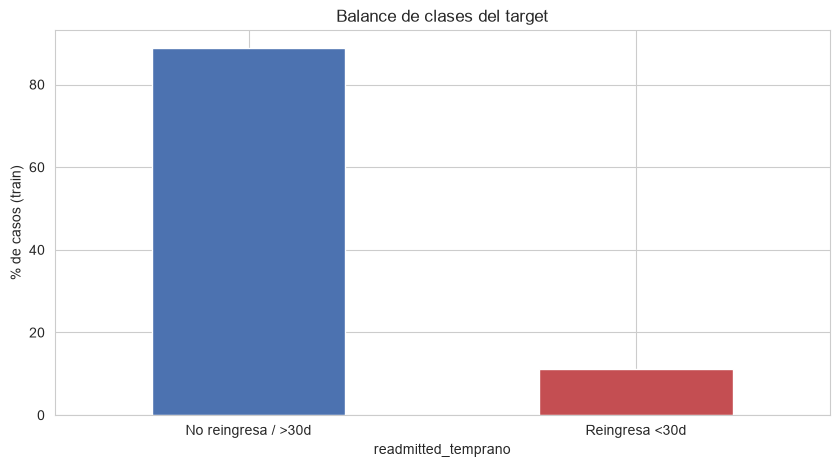

In [69]:
balance = y_train_final.value_counts(normalize=True).sort_index() * 100
print(f"Clase 0 (no reingresa o reingresa después de 30 días): {balance[0]:.1f}%")
print(f"Clase 1 (reingresa antes de 30 días):                  {balance[1]:.1f}%")

balance.plot(kind="bar", color=["#4C72B0", "#C44E52"])
plt.xticks([0, 1], ["No reingresa / >30d", "Reingresa <30d"], rotation=0)
plt.ylabel("% de casos (train)")
plt.title("Balance de clases del target")
plt.show()

El desbalance es **moderado** (~89% / 11%), no extremo, pero suficiente para que un modelo sin
ajustes tienda a "predecir siempre NO reingreso" con accuracy engañosamente alta.

### Mecanismos evaluados

Consideramos los dos mecanismos habituales para tratar el desbalance, que en caso de usarse se aplican
únicamente sobre train:

1. **Class weighting**: no modifica los datos, penaliza más los errores sobre la clase minoritaria.
2. **Undersampling aleatorio**: reduce el dataset, descarta información potencialmente útil.

**Decisión: no aplicamos ninguno de los dos.** Los modelos (notebooks 3 y 4) se entrenan con la distribución
natural de las clases y el desbalance se resuelve en el umbral de decisión, que elegimos con predicciones
fuera de fold del train (M6, notebook 3). Lo decidimos así por tres motivos:

1. Para equilibrar las clases con undersampling habría que descartar casi nueve de cada diez casos
   negativos, y con ellos información que el modelo puede aprovechar.
2. La métrica principal es el ROC-AUC, que mide cómo el modelo ordena a los pacientes por riesgo y no depende
   de un umbral, así que el desbalance no la distorsiona.
3. Sin pesos de clase, los puntajes de los modelos conservan la prevalencia real del problema (11 %), y el
   umbral se ajusta a esa escala en lugar de a una escala artificial.

Es la misma conclusión a la que llega la notebook *4 - Ensambles en clasificación* de la clase 5: ajustar el
umbral por validación cruzada y usar pesos de clase hacen esencialmente lo mismo, porque los dos corren la
frontera de decisión hacia la clase minoritaria.

La accuracy engañosa que mencionamos arriba se evita usando métricas que sí tienen en cuenta la clase
minoritaria: recall, precisión, F1, exactitud balanceada y AUC-PR.

---
## Cierre del notebook 1

Al terminar el EDA quedan definidas las 18 variables que van al modelado, su forma de codificación y el split
agrupado por paciente (71.583 filas de train y 30.180 de test, sin pacientes compartidos). También quedó
identificada la señal más fuerte del problema: los antecedentes de internación del paciente.

El notebook 2 parte de este punto: formaliza el problema de aprendizaje y construye el basal, la regla simple
que cualquier algoritmo tiene que superar.

---
### Estado de la sesión para el notebook siguiente

Se guarda el estado completo de la sesión (datos, variables y funciones definidas hasta acá) para que el
notebook siguiente continúe exactamente desde este punto, sin repetir los cálculos. El archivo queda en
`artefactos_ml/` y no se sube al repositorio por su tamaño.

In [70]:
import dill
from pathlib import Path
Path("artefactos_ml").mkdir(exist_ok=True)
dill.dump_session("artefactos_ml/estado_01.pkl")
dill.extend(False)            # deja el pickle estándar como estaba
print("Estado guardado en artefactos_ml/estado_01.pkl")

Estado guardado en artefactos_ml/estado_01.pkl
